# Tech Challenge - Fase 02
Grupo:
-
Alan Lima - RM 375783

Derick Kavabata - RM 375932

Gustavo Toledo - RM 376220

Taís Santos - RM 375962

Victor Vallim - RM 375931

#Case: Classificando a qualidade de vinhos com Machine Learning

Será utilizada a base de dados **Wine Quality Dataset**, disponível
publicamente no Kaggle, que contém informações físico-químicas de diferentes
amostras de vinho, como acidez, teor alcoólico, densidade e níveis de dióxido de
enxofre. Cada amostra também possui uma **nota de qualidade atribuída por especialistas, que será utilizada como variável alvo** para o desenvolvimento de
modelos de classificação.

Objetivo
-
Desenvolver um modelo de classificação capaz de **prever a qualidade de um vinho** com base em suas características físico-químicas. Para simplificar o
problema, a variável de qualidade deverá ser transformada em uma classificação
binária, por exemplo:

* Vinho de Alta Qualidade: nota ≥ 7

* Vinho de Baixa/Média Qualidade: nota < 7

O objetivo é treinar e avaliar modelos de aprendizado de máquina capazes de
prever essa classificação a partir das variáveis disponíveis.

Fonte: ([wine-quality-dataset](https://www.kaggle.com/datasets/yasserh/wine-quality-dataset))

O conjunto de dados contém variáveis como:
-

* Acidez fixa (fixed acidity);

* Acidez volátil (volatile acidity);

* Ácido cítrico (citric acid);

* Açúcar residual (residual sugar);

* Cloretos (chlorides);

* Dióxido de enxofre livre (free sulfur dioxide);

* Dióxido de enxofre total (total sulfur dioxide);

* Densidade (density);

* pH;

* Sulfatos (sulphates);

* Teor alcoólico (alcohol);

* Qualidade do vinho (quality).

In [ ]:
#Manipulação:
import numpy as np
import pandas as pd
from scipy import stats
#Visualização:
import matplotlib.pyplot as plt
import seaborn as sns
#Modelos de classificação:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
#Normalização de dados:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
#Regressão linear múltipla
from sklearn.linear_model import LinearRegression

In [ ]:
vinhos = pd.read_csv('/content/WineQT.csv')

#**1. Compreensão do Problema**
* Interpretar o contexto do problema.
* Definir claramente a variável alvo.
* Realizar a transformação da variável de qualidade em classificação
binária.

##Contexto do problema

In [ ]:
vinhos.sample(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
298,6.4,0.67,0.08,2.1,0.045,19.0,48.0,0.99490,3.49,0.49,11.4,6,426
271,5.6,0.85,0.05,1.4,0.045,12.0,88.0,0.99240,3.56,0.82,12.9,8,390
214,7.1,0.63,0.06,2.0,0.083,8.0,29.0,0.99855,3.67,0.73,9.6,5,297
64,8.6,0.49,0.28,1.9,0.110,20.0,136.0,0.99720,2.93,1.95,9.9,6,91
884,7.1,0.72,0.00,1.8,0.123,6.0,14.0,0.99627,3.45,0.58,9.8,5,1252


In [ ]:
# Verificando formato do DataFrame
vinhos.shape

(1143, 13)

In [ ]:
# informações gerais do dataset
vinhos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [ ]:
# descritivo das variáveis: resumo das estatísticas
vinhos.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.31,1.75,4.60,7.10,7.90,9.10,15.90
volatile acidity,1143.0,0.53,0.18,0.12,0.39,0.52,0.64,1.58
citric acid,1143.0,0.27,0.20,0.00,0.09,0.25,0.42,1.00
residual sugar,1143.0,2.53,1.36,0.90,1.90,2.20,2.60,15.50
chlorides,1143.0,0.09,0.05,0.01,0.07,0.08,0.09,0.61
free sulfur dioxide,1143.0,15.62,10.25,1.00,7.00,13.00,21.00,68.00
total sulfur dioxide,1143.0,45.91,32.78,6.00,21.00,37.00,61.00,289.00
density,1143.0,1.00,0.00,0.99,1.00,1.00,1.00,1.00
pH,1143.0,3.31,0.16,2.74,3.20,3.31,3.40,4.01
sulphates,1143.0,0.66,0.17,0.33,0.55,0.62,0.73,2.00


In [ ]:
# Analisando valores nulos na base
vinhos.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [ ]:
# Estatísticas das classes dos vinhos
vinhos['quality'].describe()

,quality
count,1143.000000
mean,5.657043
std,0.805824
min,3.000000
25%,5.000000
50%,6.000000
75%,6.000000
max,8.000000


Nota-se que a média de nota dos vinhos fica em torno de 5.6, e desvio padrão é pequeno (0.8). Assim, pode-se dizer que a maioria dos vinhos do dataset são de nota 5 ou próximo, como é observado na quantificação dos quartis.

In [ ]:
# Conferindo quais valores existem na coluna 'quality'
set(vinhos['quality'])

{3, 4, 5, 6, 7, 8}

In [ ]:
# Quantidade de vinhos para cada nota de qualidade:
vinhos.groupby('quality')[['Id']].count()

,Id
quality,
3,6
4,33
5,483
6,462
7,143
8,16


Contando a quantidade de vinhos por nota, percebe-se que os dados estão desequilibrados. Existem muito menos vinhos de alta qualidade (notas 7 e 8), do que de média e baixa (notas 3 a 6).

##Identificando a variável target

Como queremos criar um modelo que classifique vinhos pela nota de qualidade atribuída, a variavel alvo será aquela contida na coluna ```'quality'```.

Vamos verificar a distribuição dos vinhos de acordo com a nota:

Text(0.5, 1.0, 'Histograma quality')

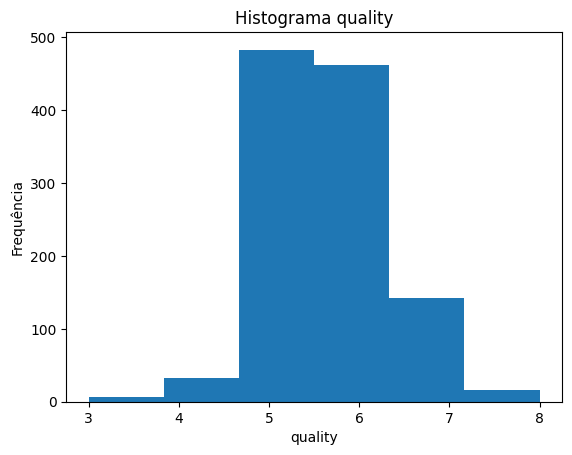

In [ ]:
# Histograma da variável target

plt.hist(vinhos['quality'], bins=6)
plt.ylabel('Frequência')
plt.xlabel('quality')
plt.title('Histograma quality')

Text(0.5, 1.0, 'Histograma raiz_qualidade')

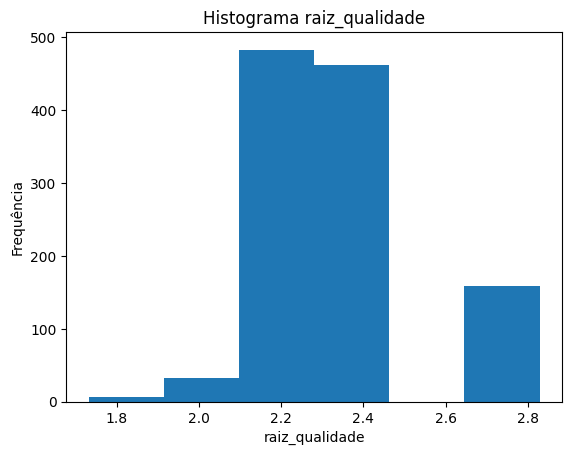

In [ ]:
# Transformando para raiz quadrada para uma distribuição mais proporcional dos dados:
vinhos['raiz_qualidade'] = np.sqrt(vinhos['quality'])

plt.hist((vinhos['raiz_qualidade']), bins=6)
plt.ylabel('Frequência')
plt.xlabel('raiz_qualidade')
plt.title('Histograma raiz_qualidade')

##Dividindo a variável target em categoria binária

In [ ]:
# Para categorização, vamos dividir os vinhos em 2 categorias diferentes: Baixa, e Alta

def categorizar_vinho(quality): # Definindo função para categorizar:
  if quality <7:
    return 0 # Vinhos com nota 6 ou inferior não serão de alta qualidade
  else:
    return 1

# Aplicando função e criando nova coluna:
vinhos['Alta Qualidade'] = vinhos['quality'].apply(categorizar_vinho)

vinhos.sample(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,raiz_qualidade,Alta Qualidade
1132,6.2,0.46,0.29,2.1,0.074,32.0,98.0,0.99578,3.33,0.62,9.8,5,1583,2.236068,0
319,10.4,0.33,0.63,2.8,0.084,5.0,22.0,0.99980,3.26,0.74,11.2,7,453,2.645751,1
410,10.2,0.24,0.49,2.4,0.075,10.0,28.0,0.99780,3.14,0.61,10.4,5,572,2.236068,0
471,7.2,0.57,0.06,1.6,0.076,9.0,27.0,0.99720,3.36,0.70,9.6,6,662,2.449490,0
608,9.3,0.36,0.39,1.5,0.080,41.0,55.0,0.99652,3.47,0.73,10.9,6,853,2.449490,0


In [ ]:
# Quantidade de vinhos para cada categoria:
vinhos.groupby('Alta Qualidade')['Id'].count().sort_values(ascending=False)

,Id
Alta Qualidade,
0,984
1,159


In [ ]:
# Criando filtros e separando em dataframes para cada categoria
filtro_alta_qualidade = vinhos['Alta Qualidade'] == 1
filtro_baixa_qualidade = vinhos['Alta Qualidade'] == 0

vinhos_alta = vinhos[filtro_alta_qualidade]
vinhos_baixa = vinhos[filtro_baixa_qualidade]

In [ ]:
vinhos_alta.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,159.0,8.846541,2.097038,4.900000,7.400000,8.700000,10.100000,15.600000
volatile acidity,159.0,0.395314,0.134869,0.120000,0.300000,0.360000,0.480000,0.850000
citric acid,159.0,0.391195,0.195116,0.000000,0.320000,0.410000,0.520000,0.760000
residual sugar,159.0,2.748428,1.400818,1.200000,1.900000,2.300000,2.800000,8.300000
chlorides,159.0,0.074711,0.029154,0.012000,0.062000,0.073000,0.083500,0.358000
free sulfur dioxide,159.0,14.188679,9.903279,3.000000,6.000000,12.000000,17.500000,53.000000
total sulfur dioxide,159.0,36.672956,35.612808,8.000000,18.000000,28.000000,43.000000,289.000000
density,159.0,0.996019,0.002283,0.990640,0.994610,0.995680,0.997350,1.003200
pH,159.0,3.282453,0.156297,2.880000,3.200000,3.270000,3.375000,3.780000
sulphates,159.0,0.745849,0.141459,0.390000,0.660000,0.740000,0.835000,1.360000


In [ ]:
vinhos_baixa.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,984.0,8.224593,1.669548,4.600000,7.100000,7.800000,9.00000,15.90000
volatile acidity,984.0,0.553318,0.176316,0.160000,0.430000,0.550000,0.66000,1.58000
citric acid,984.0,0.248516,0.189707,0.000000,0.080000,0.240000,0.40000,1.00000
residual sugar,984.0,2.497205,1.345994,0.900000,1.900000,2.200000,2.60000,15.50000
chlorides,984.0,0.088908,0.049304,0.034000,0.071000,0.080000,0.09100,0.61100
free sulfur dioxide,984.0,15.846037,10.291822,1.000000,7.000000,14.000000,21.00000,68.00000
total sulfur dioxide,984.0,47.408028,32.071725,6.000000,22.000000,39.000000,64.00000,165.00000
density,984.0,0.996845,0.001836,0.990070,0.995727,0.996765,0.99790,1.00369
pH,984.0,3.315630,0.156313,2.740000,3.210000,3.315000,3.41000,4.01000
sulphates,984.0,0.643465,0.170459,0.330000,0.540000,0.600000,0.69250,2.00000


Comparando-se as duas classes, nota-se que as médias e desvios dos valores fisio-químicos permanecem relativamente próximos de modo geral. Algumas poucas exceções são a acidez volátil, mais baixa na classe de Alta Qualidade; ácido cítrico, mais baixo na classe Alta Qualidade; sulfatos e álcool, levemente mais concentrados nos vinhos de alta qualidade.

#**2. Análise Exploratória de Dados (EDA)**
 * Investigar a distribuição das variáveis
 * Identificar correlações entre as variáveis e justificar cada uma delas.
 * Detectar possíveis outliers ou valores inconsistentes.
 * Analisar o balanceamento das classes.

##Distribuição de variáveis quantitativas

Buscando Outliers

Text(0, 0.5, 'Álcool')

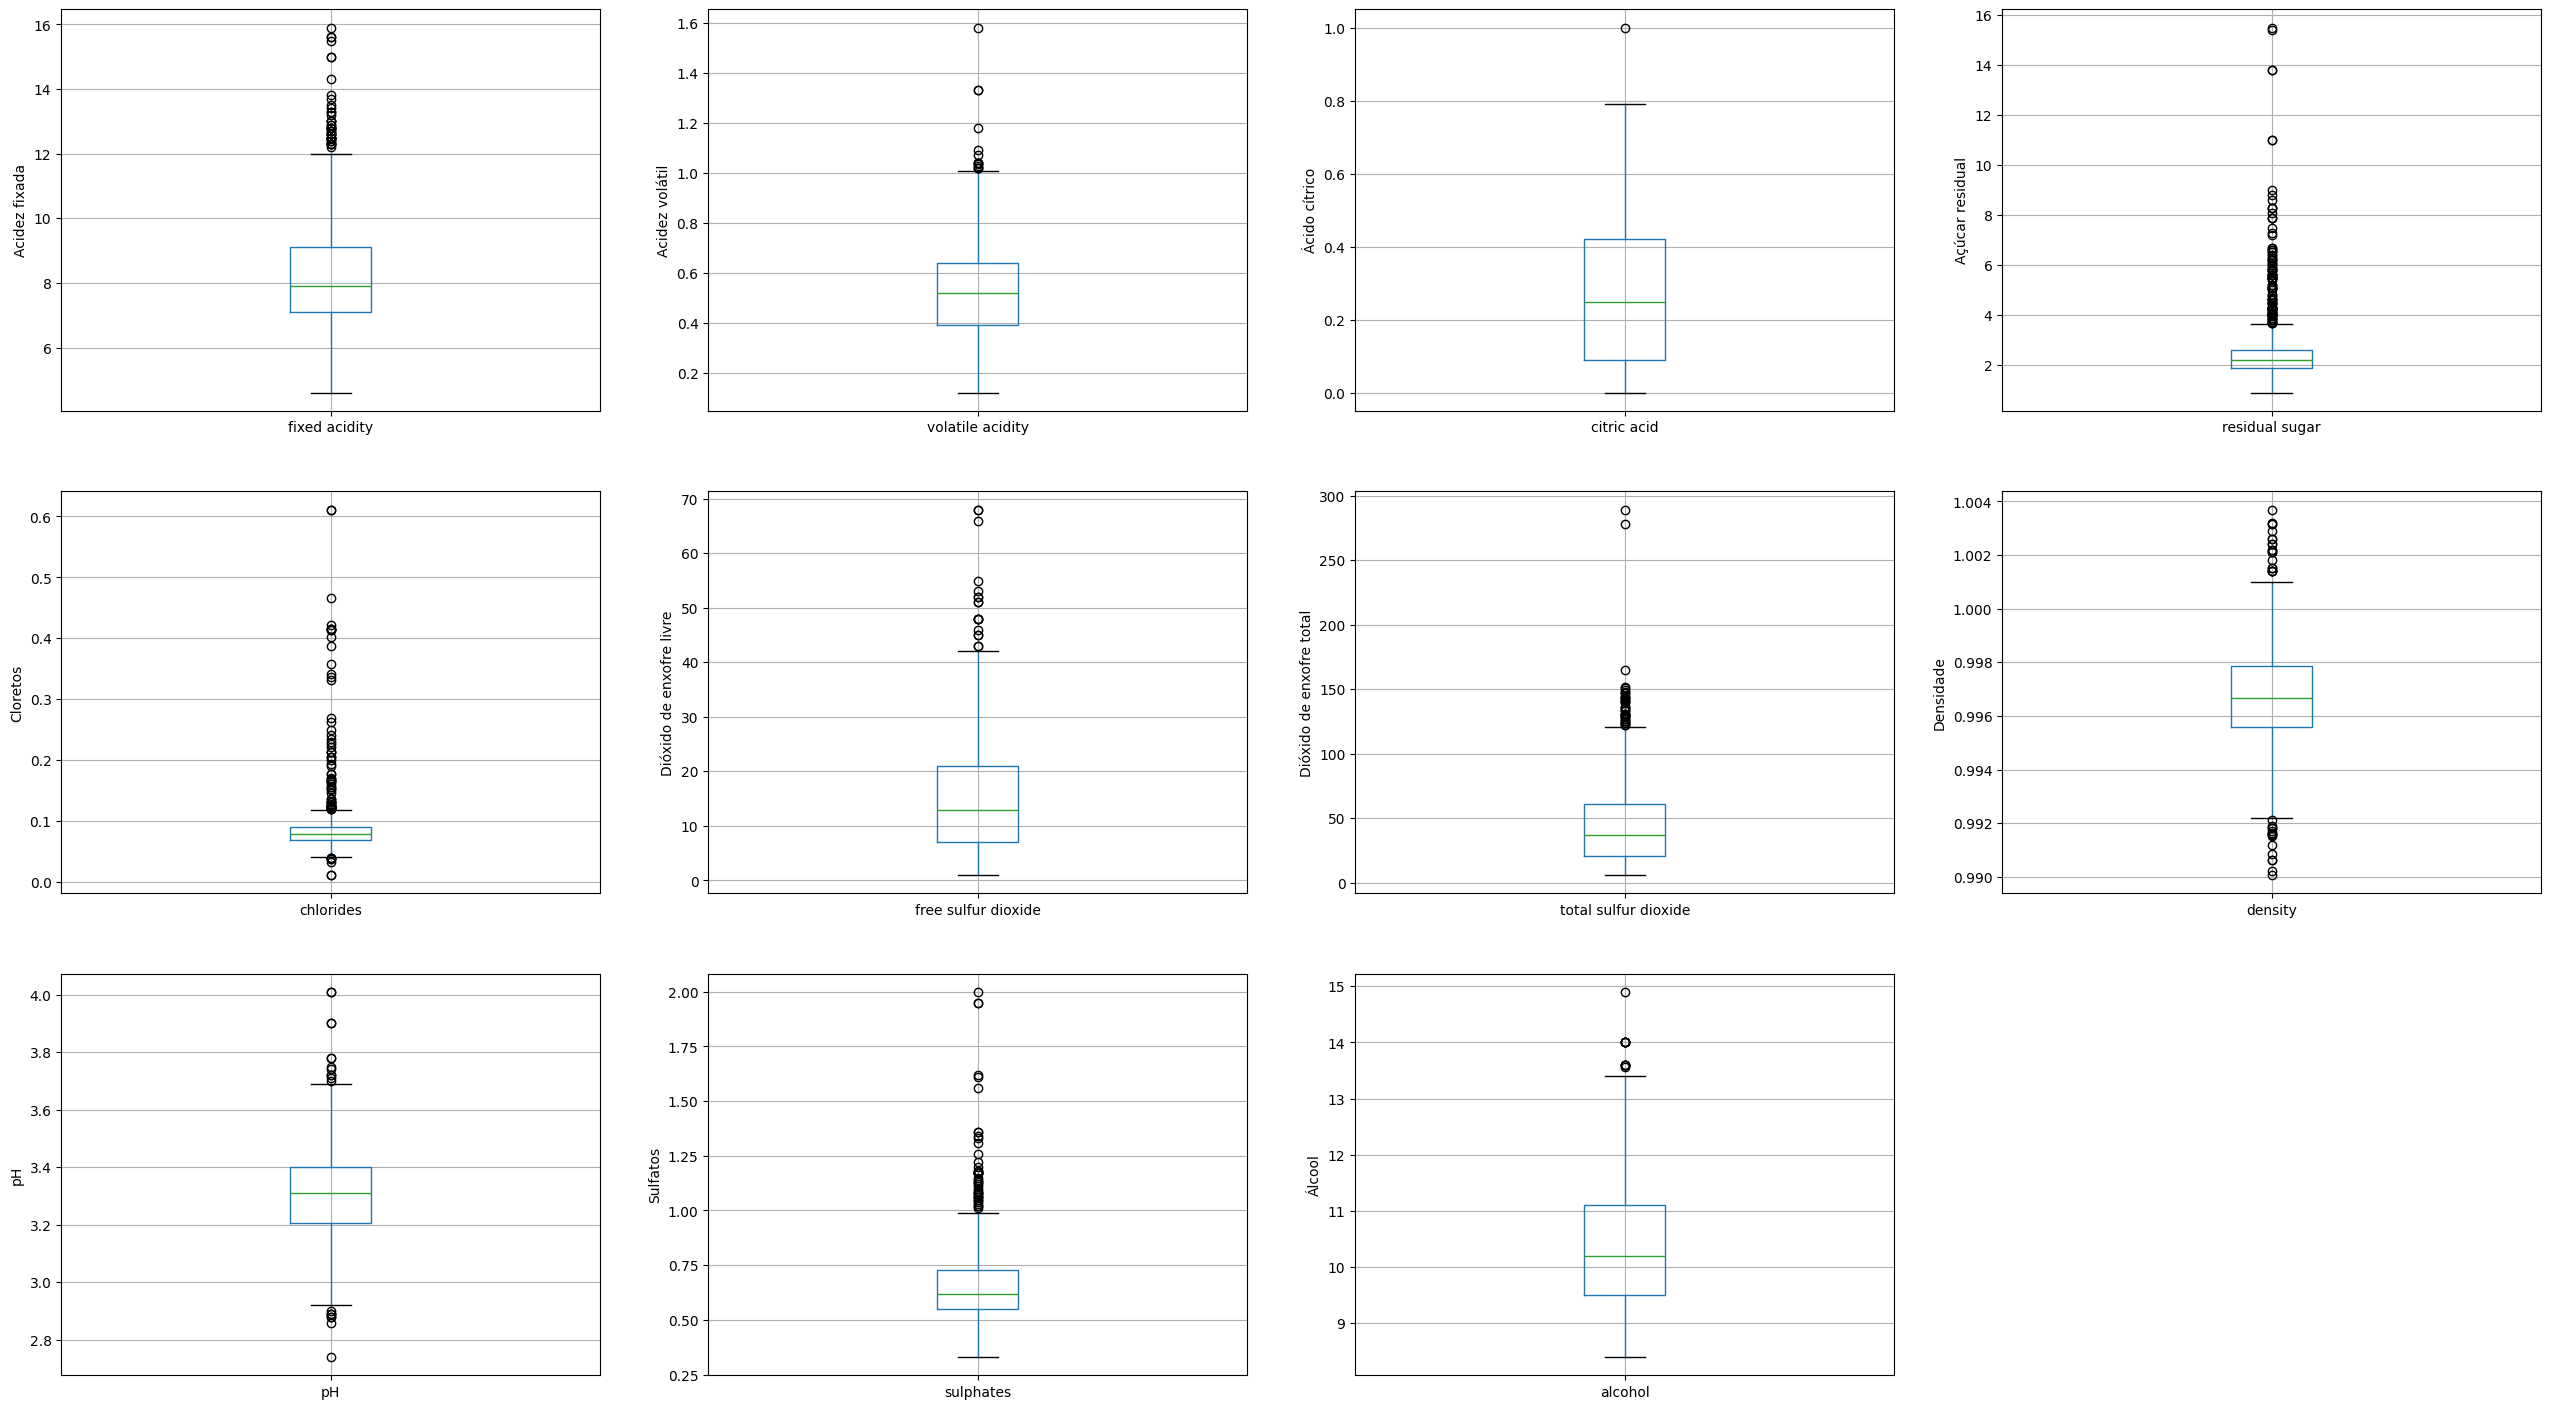

In [ ]:
# Avaliando as variáveis quantitativas por Boxplot para visualizar Outliers

plt.figure(figsize=(32,24))


plt.subplot(4, 4, 1)
fig = vinhos.boxplot(column='fixed acidity')
fig.set_title('')
fig.set_ylabel('Acidez fixada')

plt.subplot(4, 4, 2)
fig = vinhos.boxplot(column='volatile acidity')
fig.set_title('')
fig.set_ylabel('Acidez volátil')

plt.subplot(4, 4, 3)
fig = vinhos.boxplot(column='citric acid')
fig.set_title('')
fig.set_ylabel('Ácido cítrico')

plt.subplot(4, 4, 4)
fig = vinhos.boxplot(column='residual sugar')
fig.set_title('')
fig.set_ylabel('Açúcar residual')

plt.subplot(4, 4, 5)
fig = vinhos.boxplot(column='chlorides')
fig.set_title('')
fig.set_ylabel('Cloretos')

plt.subplot(4, 4, 6)
fig = vinhos.boxplot(column='free sulfur dioxide')
fig.set_title('')
fig.set_ylabel('Dióxido de enxofre livre')

plt.subplot(4, 4, 7)
fig = vinhos.boxplot(column='total sulfur dioxide')
fig.set_title('')
fig.set_ylabel('Dióxido de enxofre total')

plt.subplot(4, 4, 8)
fig = vinhos.boxplot(column='density')
fig.set_title('')
fig.set_ylabel('Densidade')

plt.subplot(4, 4, 9)
fig = vinhos.boxplot(column='pH')
fig.set_title('')
fig.set_ylabel('pH')

plt.subplot(4, 4, 10)
fig = vinhos.boxplot(column='sulphates')
fig.set_title('')
fig.set_ylabel('Sulfatos')

plt.subplot(4, 4, 11)
fig = vinhos.boxplot(column='alcohol')
fig.set_title('')
fig.set_ylabel('Álcool')



Nota-se grande quantidade de outliers para a maioria das propriedades químicas dos vinhos, com destaque para Acidez Fixada, Cloretos, Sulfatos  e Açúcar Residual.

A propriedade com menor quantidade de outliers é o Ácido Cítrico.

## Analisando correlações

Checando se existe influência das propriedades fisio-químicas para a note de avaliação dos vinhos. Para isso, utilizaremos a Correlação de Pearson, utilizada para quando as variáveis são núméricas quantitativas:

- ρ = 0,9 a 1 (positivo ou negativo): correlação muito forte;
- ρ = 0,7 a 0,9 (positivo ou negativo): correlação forte;
- ρ = 0,5 a 0,7 (positivo ou negativo): correlação moderada;
- ρ = 0,3 a 0,5 (positivo ou negativo): correlação fraca;
- ρ = 0 a 0,3 (positivo ou negativo): não possui correlação.

In [ ]:
matriz_corr = vinhos.select_dtypes(np.number).corr()
matriz_corr.round(3)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,raiz_qualidade,Alta Qualidade
fixed acidity,1.000,-0.251,0.673,0.172,0.108,-0.165,-0.111,0.682,-0.685,0.175,-0.075,0.122,-0.276,0.120,0.123
volatile acidity,-0.251,1.000,-0.544,-0.006,0.056,-0.002,0.078,0.017,0.221,-0.276,-0.204,-0.407,-0.008,-0.410,-0.305
citric acid,0.673,-0.544,1.000,0.176,0.245,-0.058,0.037,0.375,-0.546,0.331,0.106,0.241,-0.139,0.236,0.251
residual sugar,0.172,-0.006,0.176,1.000,0.071,0.165,0.191,0.380,-0.117,0.017,0.058,0.022,-0.046,0.020,0.064
chlorides,0.108,0.056,0.245,0.071,1.000,0.015,0.048,0.209,-0.278,0.375,-0.230,-0.124,-0.088,-0.123,-0.104
free sulfur dioxide,-0.165,-0.002,-0.058,0.165,0.015,1.000,0.661,-0.054,0.073,0.034,-0.047,-0.063,0.095,-0.059,-0.056
total sulfur dioxide,-0.111,0.078,0.037,0.191,0.048,0.661,1.000,0.050,-0.059,0.027,-0.188,-0.183,-0.107,-0.179,-0.113
density,0.682,0.017,0.375,0.380,0.209,-0.054,0.050,1.000,-0.353,0.143,-0.495,-0.175,-0.364,-0.172,-0.149
pH,-0.685,0.221,-0.546,-0.117,-0.278,0.073,-0.059,-0.353,1.000,-0.185,0.225,-0.052,0.133,-0.052,-0.073
sulphates,0.175,-0.276,0.331,0.017,0.375,0.034,0.027,0.143,-0.185,1.000,0.094,0.258,-0.104,0.255,0.208


<Axes: >

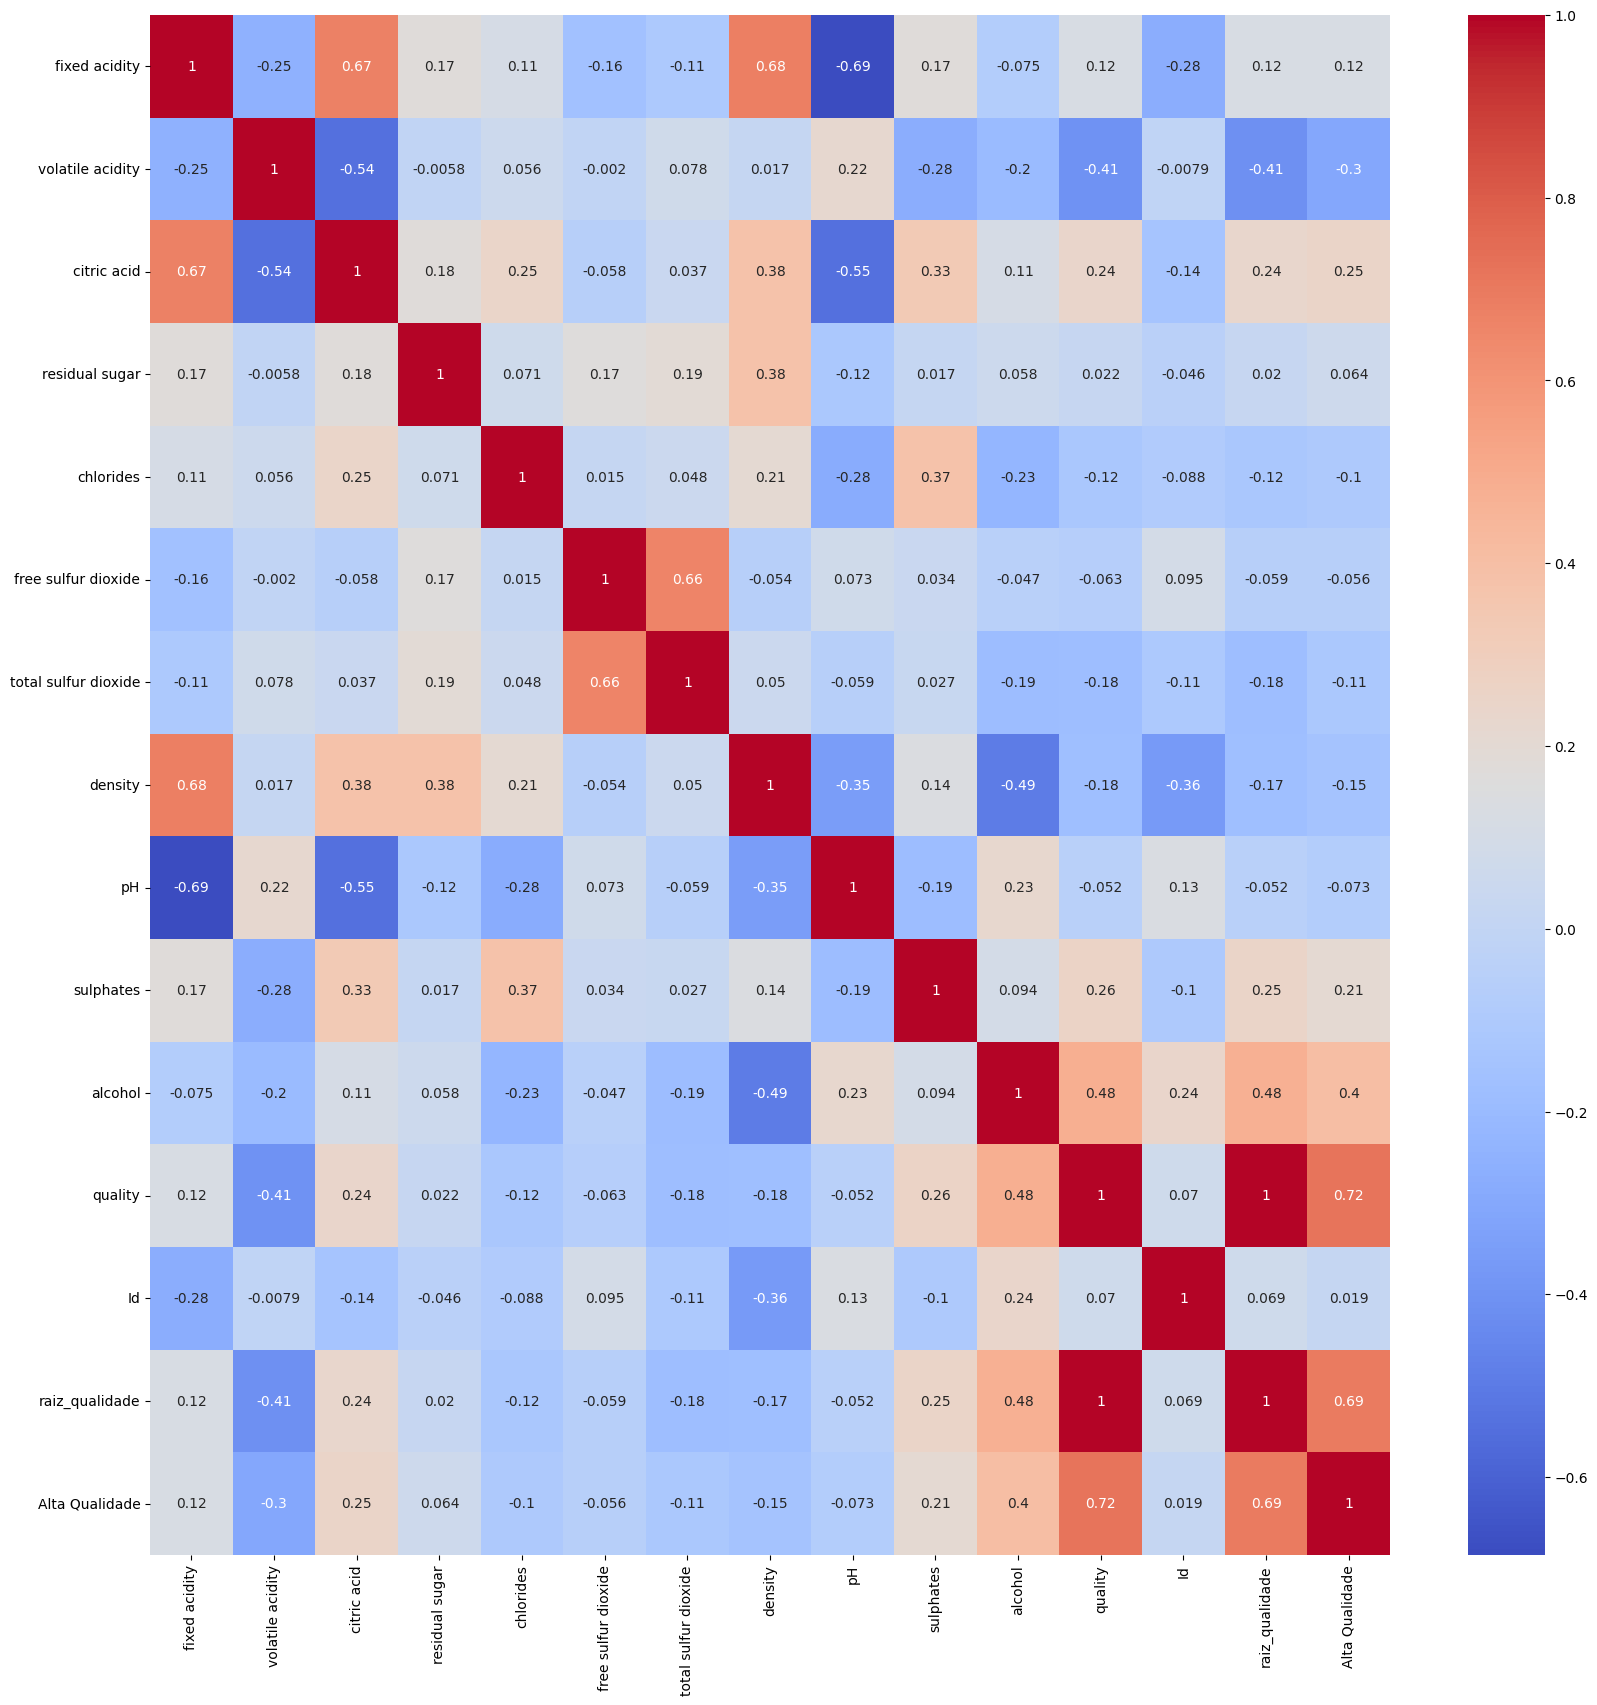

In [ ]:
# Plotando para facilitar a visualização:

fig, ax = plt.subplots(figsize=(20,20))
sns.heatmap(matriz_corr, annot=True, ax=ax, cmap = 'coolwarm')

In [ ]:
# Verificando apenas para as notas de qualidade

correlacao_qualidade = vinhos.select_dtypes(np.number).corr()
corr_qualidade = correlacao_qualidade[['quality', 'raiz_qualidade', 'Alta Qualidade']]
corr_qualidade

,quality,raiz_qualidade,Alta Qualidade
fixed acidity,0.121970,0.119704,0.123212
volatile acidity,-0.407394,-0.409702,-0.304523
citric acid,0.240821,0.236261,0.251146
residual sugar,0.022002,0.019542,0.064145
chlorides,-0.124085,-0.122999,-0.103985
free sulfur dioxide,-0.063260,-0.059101,-0.055977
total sulfur dioxide,-0.183339,-0.178681,-0.113373
density,-0.175208,-0.172166,-0.148670
pH,-0.052453,-0.052289,-0.073318
sulphates,0.257710,0.254680,0.208020


Dada a variação entre os valores de correlação para a nota bruta ('quality'), sua raiz e sua classificação, optou-se por considerar apenas a coluna da nota bruta 'quality'

<Axes: >

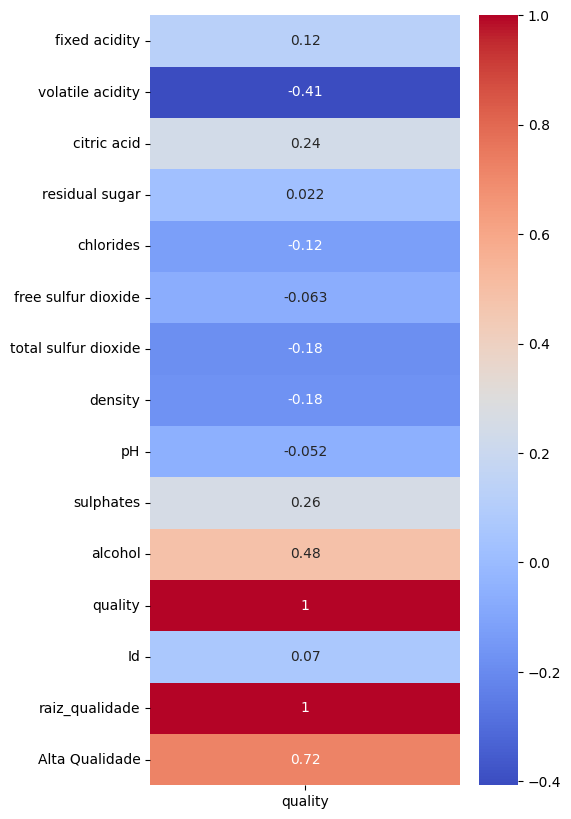

In [ ]:
corr_nota = correlacao_qualidade['quality']

fig, ax = plt.subplots(figsize=(5,10))
sns.heatmap(corr_nota.to_frame(), annot=True, cmap = 'coolwarm')

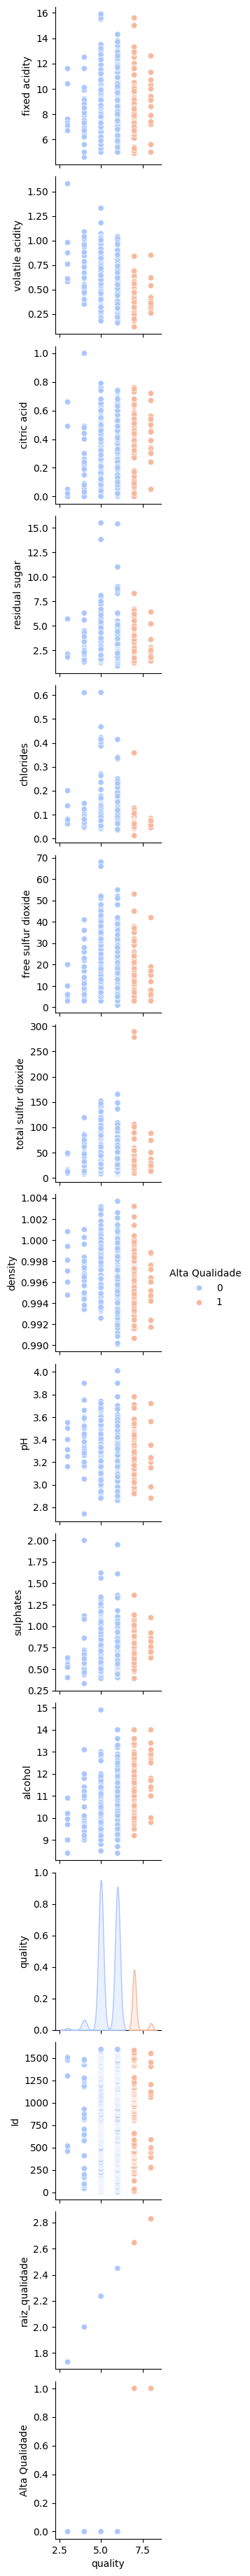

In [ ]:
#Verificando possíveis correlações entre as variáveis e a qualidade
sns.pairplot(x_vars = 'quality', y_vars= vinhos.columns, hue = 'Alta Qualidade', data = vinhos, palette = 'coolwarm');

Aparentemente, existe uma correlação positiva com o teor alcoólico (0.48).

Correlções positivas, porém bem fracas, são observadas em relação à concentração de sulfatos (0.26) e ao ácido cítrico (0.24).

Ainda, uma correlação negativa é observada sobre a acidez volátil (-0.41).

Vamos observar tais correlações num gráfico de dispersão.

## Explorando relações entre a variável dependente/target (valor de 'quality') e suas correlatas

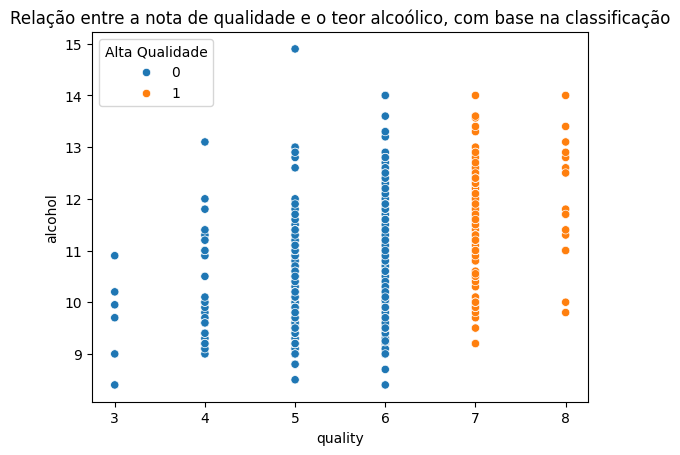

In [ ]:
# Gráfico de dispersão alcohol x quality (p = 0.48)

sns.scatterplot(x='quality', y='alcohol', hue='Alta Qualidade', data=vinhos, palette='tab10')
plt.xlabel('quality')
plt.ylabel('alcohol')
plt.title('Relação entre a nota de qualidade e o teor alcoólico, com base na classificação')
plt.show()

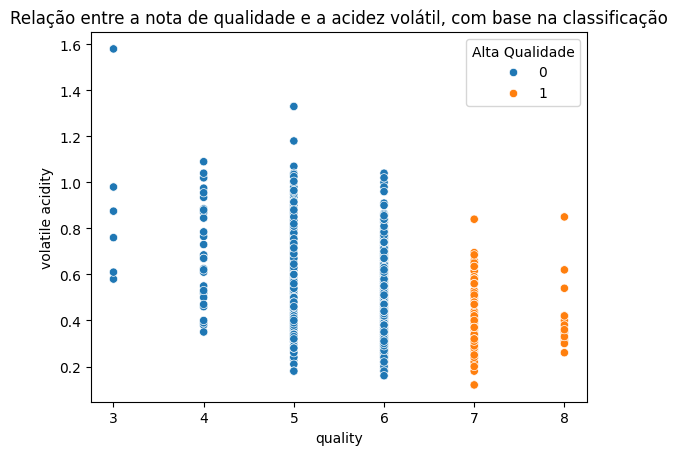

In [ ]:
# Gráfico de dispersão volatile acidity x quality (p = -0.41)

sns.scatterplot(x='quality', y='volatile acidity', hue='Alta Qualidade', data=vinhos, palette='tab10')
plt.xlabel('quality')
plt.ylabel('volatile acidity')
plt.title('Relação entre a nota de qualidade e a acidez volátil, com base na classificação')
plt.show()

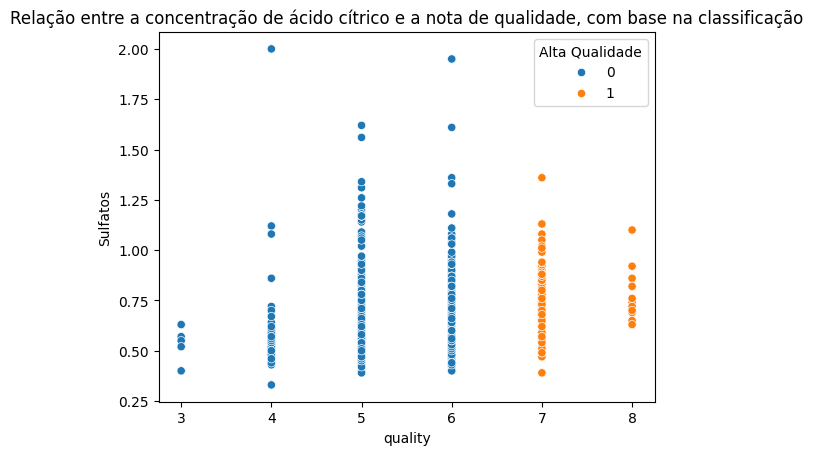

In [ ]:
#Gráfico de dispersão sulphates x quality (p = 0.26)
sns.scatterplot(x='quality', y='sulphates', hue='Alta Qualidade', data=vinhos, palette='tab10')
plt.xlabel('quality')
plt.ylabel('Sulfatos')
plt.title('Relação entre a concentração de ácido cítrico e a nota de qualidade, com base na classificação')
plt.show()


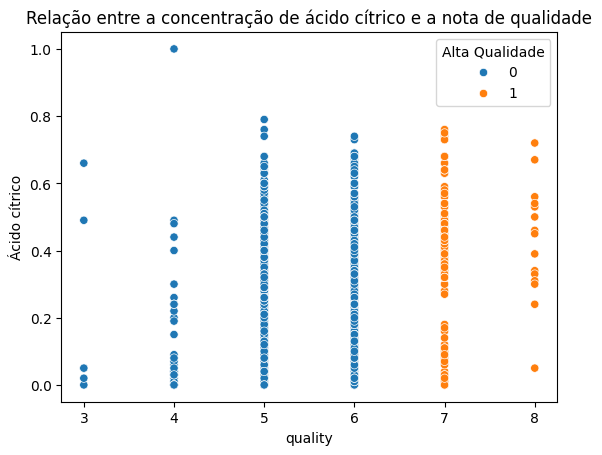

In [ ]:
#Gráfico de dispersão citric acid x quality (0.24)

sns.scatterplot(x='quality', y='citric acid', hue='Alta Qualidade', data=vinhos, palette='tab10')
plt.xlabel('quality')
plt.ylabel('Ácido cítrico')
plt.title('Relação entre a concentração de ácido cítrico e a nota de qualidade')
plt.show()

##Testes estatísticos

In [ ]:
# Quantidade de vinhos para cada nota de qualidade:
vinhos.groupby('quality')[['Id']].count()

,Id
quality,
3,6
4,33
5,483
6,462
7,143
8,16


In [ ]:
# Quantidade de vinhos por classe:
vinhos.groupby('Alta Qualidade')[['Id']].count()

,Id
Alta Qualidade,
0,984
1,159


In [ ]:
vinhos['quality'].describe()

,quality
count,1143.000000
mean,5.657043
std,0.805824
min,3.000000
25%,5.000000
50%,6.000000
75%,6.000000
max,8.000000


Text(0.5, 0, 'Nota Qualidade')

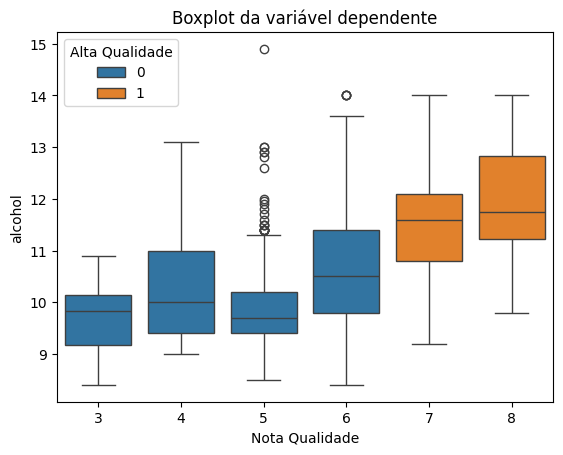

In [ ]:
sns.boxplot(x='quality', y='alcohol', hue = 'Alta Qualidade', data=vinhos)
plt.title('Boxplot da variável dependente')
plt.xlabel('Nota Qualidade')

Text(0.5, 0, 'Nota Qualidade')

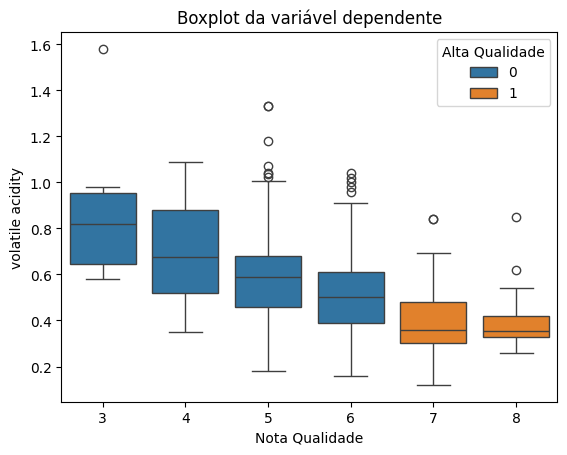

In [ ]:
sns.boxplot(x='quality', y='volatile acidity', hue = 'Alta Qualidade', data=vinhos)
plt.title('Boxplot da variável dependente')
plt.xlabel('Nota Qualidade')

Text(0.5, 0, 'Nota qualidade')

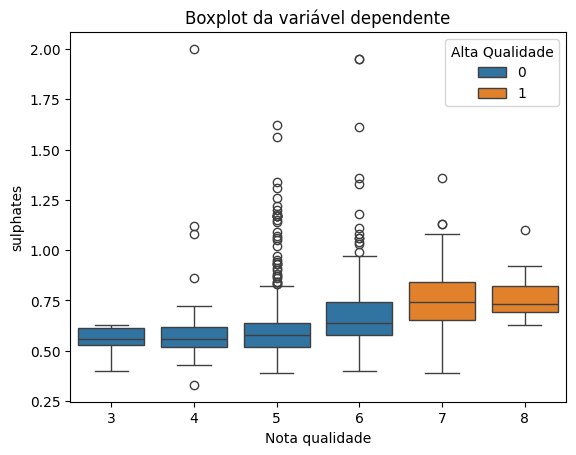

In [ ]:
sns.boxplot(x='quality', y='sulphates', hue = 'Alta Qualidade', data=vinhos)
plt.title('Boxplot da variável dependente')
plt.xlabel('Nota qualidade')

Text(0.5, 0, 'Nota qualidade')

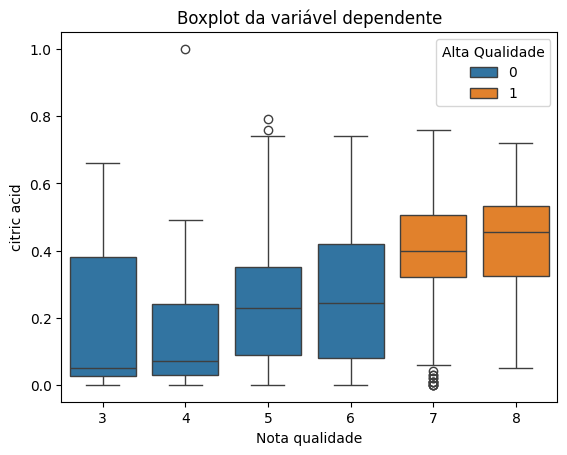

In [ ]:
sns.boxplot(x='quality', y='citric acid', hue = 'Alta Qualidade', data=vinhos)
plt.title('Boxplot da variável dependente')
plt.xlabel('Nota qualidade')

Axes(0.125,0.11;0.775x0.77)
Axes(0.125,0.11;0.775x0.77)


Text(0.5, 0, 'Alta Qualidade')

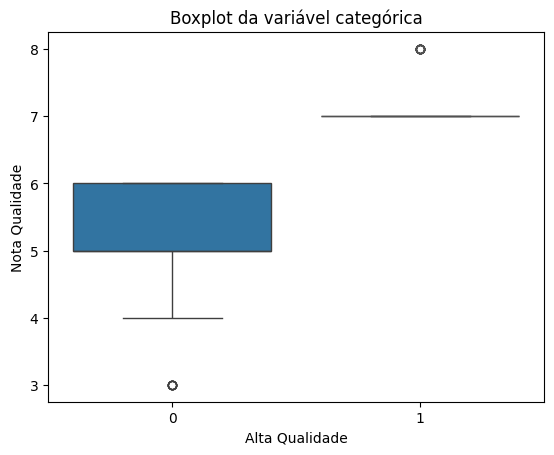

In [ ]:
#Boxplot da variável categórica Qualidade:
print(sns.boxplot(vinhos_baixa, x = 'Alta Qualidade', y='quality'))
print(sns.boxplot(vinhos_alta, x = 'Alta Qualidade', y='quality'))
plt.title('Boxplot da variável categórica')
plt.ylabel('Nota Qualidade')
plt.xlabel('Alta Qualidade')

## Boxplot da variável dependente x variável categórica

Axes(0.125,0.11;0.775x0.77)
Axes(0.125,0.11;0.775x0.77)


Text(0.5, 1.0, 'Boxplot da variável dependente x variável categórica')

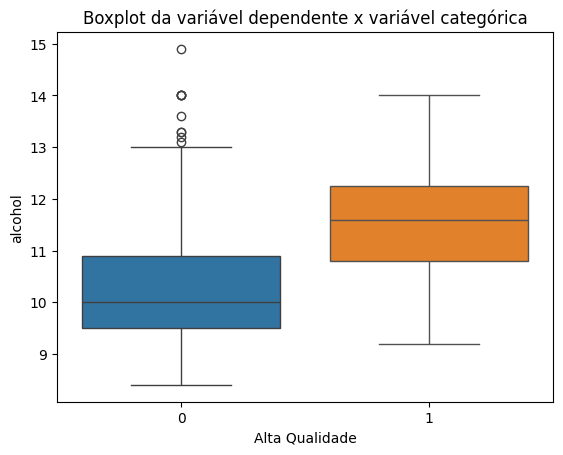

In [ ]:
print(sns.boxplot(vinhos_baixa, x = 'Alta Qualidade', y='alcohol'))
print(sns.boxplot(vinhos_alta, x = 'Alta Qualidade', y='alcohol'))
plt.title('Boxplot da variável dependente x variável categórica')

Axes(0.125,0.11;0.775x0.77)
Axes(0.125,0.11;0.775x0.77)


Text(0.5, 1.0, 'Boxplot da variável dependente x variável categórica')

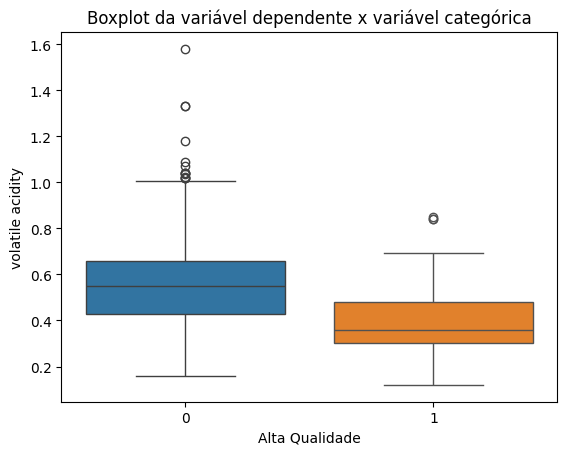

In [ ]:
print(sns.boxplot(vinhos_baixa, x = 'Alta Qualidade', y='volatile acidity'))
print(sns.boxplot(vinhos_alta, x = 'Alta Qualidade', y='volatile acidity'))
plt.title('Boxplot da variável dependente x variável categórica')

Axes(0.125,0.11;0.775x0.77)
Axes(0.125,0.11;0.775x0.77)


Text(0.5, 1.0, 'Boxplot da variável dependente x variável categórica')

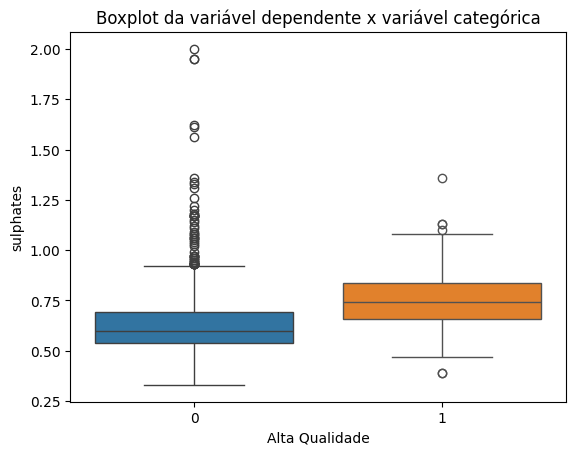

In [ ]:
print(sns.boxplot(vinhos_baixa, x = 'Alta Qualidade', y='sulphates'))
print(sns.boxplot(vinhos_alta, x = 'Alta Qualidade', y='sulphates'))
plt.title('Boxplot da variável dependente x variável categórica')

Axes(0.125,0.11;0.775x0.77)
Axes(0.125,0.11;0.775x0.77)


Text(0.5, 1.0, 'Boxplot da variável dependente x variável categórica')

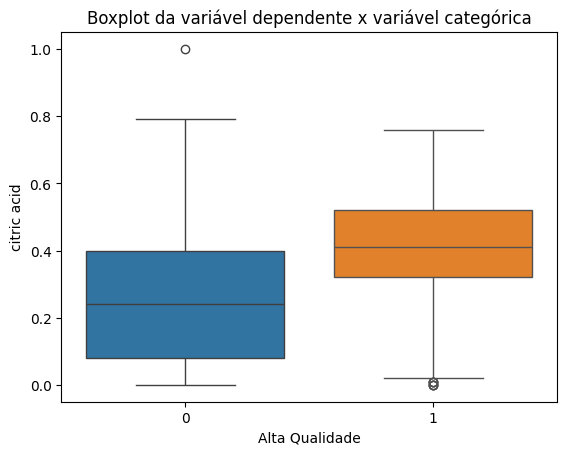

In [ ]:
print(sns.boxplot(vinhos_baixa, x = 'Alta Qualidade', y='citric acid'))
print(sns.boxplot(vinhos_alta, x = 'Alta Qualidade', y='citric acid'))
plt.title('Boxplot da variável dependente x variável categórica')

#**3. Pré-processamento de Dados**

* Tratamento de dados faltantes (se houver).

* Normalização ou padronização de variáveis numéricas.

* Criação de novas features (feature engineering), se considerado
relevante.

##Verificando dados faltantes

In [ ]:
vinhos.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


##Separação dos dados

In [ ]:
#Importando separador:
from sklearn.model_selection import train_test_split

Para separação dos dados em treino e teste, vamos considerar apenas aquelas variáveis que possuíam alguma correlação com a nota de qualidade, afim de não confundir e/ou sobrecarregar o modelo com dados irrelevantes.

In [ ]:
#Separando os dados em treino e teste:
X = vinhos[['volatile acidity','alcohol','sulphates','citric acid']] # Variáveis características
y = vinhos['Alta Qualidade'] # Variável alvo

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 99)

In [ ]:
#verificando bases de treino e teste:
print('Base de treino:', len(X_train),'vinhos')
print('\nQuantidade de vinhos por classe na base de treino: \n', y_train.value_counts())
print('\nBase de teste:', len(X_test),'vinhos')
print('\nProporção:', len(X_test)/len(X_train))

#Gabarito:
print('\nQuantidade de vinhos para cada Classe no dataset de teste (gabarito):\n', y_test.value_counts().sort_index())

Base de treino: 914 vinhos

Quantidade de vinhos por classe na base de treino: 
 Alta Qualidade
0    792
1    122
Name: count, dtype: int64

Base de teste: 229 vinhos

Proporção: 0.25054704595185995

Quantidade de vinhos para cada Classe no dataset de teste (gabarito):
 Alta Qualidade
0    192
1     37
Name: count, dtype: int64


## Checando distribuição
Verificando o balanceamento dos dados para as classes de vinho:

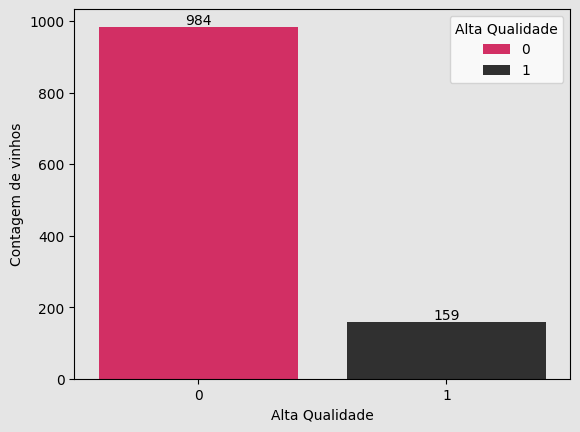

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(facecolor='#E5E5E5')
ax.set_facecolor('#E5E5E5')

sns.countplot(
    x='Alta Qualidade',
    hue='Alta Qualidade',
    data=vinhos,
    palette=['#ED145B', '#303030'],
    ax=ax
)

ax.set(ylabel='Contagem de vinhos')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

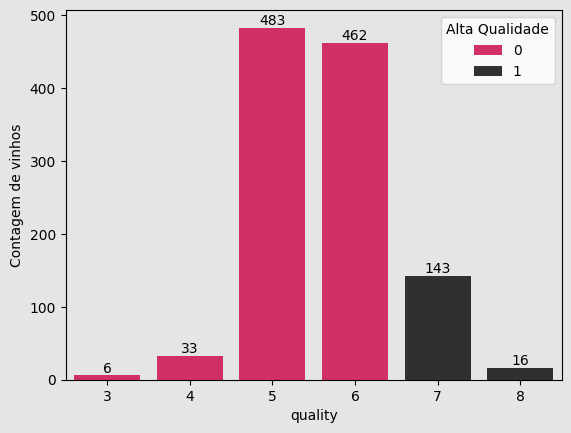

In [ ]:
fig, ax = plt.subplots(facecolor='#E5E5E5')
ax.set_facecolor('#E5E5E5')

sns.countplot(
    x='quality',
    hue='Alta Qualidade',
    data=vinhos,
    palette=['#ED145B', '#303030'],
    ax=ax
)

ax.set(ylabel='Contagem de vinhos')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

Nota-se que, tanto para as classe binária Alta Qualidade quanto para as notas brutas, os dados encontram-se extremamente desbalanceados, necessitando-se assim um balanceamento de valores.

In [ ]:
# Checando novamente distribuição dos dados na base de treino:
y_train.value_counts()

,count
Alta Qualidade,
0,792
1,122


## Normalização dos dados
Será feita apenas na base de treino (```X_train```), para aplicar pesos semelhantes à cada atributo e para não enviezar o modelo .

In [ ]:
# Importando ferramentas de normalização e padronização
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [ ]:
X_train

,volatile acidity,alcohol,sulphates,citric acid
574,0.37,10.8,0.81,0.44
17,0.40,9.7,0.63,0.14
64,0.49,9.9,1.95,0.28
671,0.28,12.4,0.62,0.48
806,0.40,9.5,0.65,0.30
...,...,...,...,...
55,0.45,9.2,0.56,0.20
919,0.63,9.5,0.45,0.00
1092,0.44,11.3,0.69,0.09
1059,0.33,10.7,0.61,0.44


In [ ]:
scaler_min_max = MinMaxScaler() # Método de normalização dos dados (0-1)

scaler_min_max.fit(X_train) #Aplicar apenas na base de treino para nao enviezar o modelo
                     #A ideia é, obviamente, testar o modelo com dados reais

x_train_min_max = scaler_min_max.transform(X_train)
x_test_min_max = scaler_min_max.transform(X_test)

x_train_min_max


array([[0.17123288, 0.36923077, 0.28742515, 0.44      ],
       [0.19178082, 0.2       , 0.17964072, 0.14      ],
       [0.25342466, 0.23076923, 0.97005988, 0.28      ],
       ...,
       [0.21917808, 0.44615385, 0.21556886, 0.09      ],
       [0.14383562, 0.35384615, 0.16766467, 0.44      ],
       [0.30136986, 0.47692308, 0.1257485 , 0.        ]])

## Padronizando dados
É feita apenas com a base de treino (```X_train```), para nao enviezar o modelo e aplicar pesos semelhantes à cada atributo.

In [ ]:
scaler_std = StandardScaler() # Método de padronização dos dados (média e std)

scaler_std.fit(X_train) # Qual média e std vai ser usada para o escalonamento

x_train_std = scaler_std.transform(X_train)
x_test_std = scaler_std.transform(X_test)

x_train_std

array([[-0.89298699,  0.33007479,  0.88776487,  0.88423819],
       [-0.72675118, -0.67534996, -0.15503876, -0.64498358],
       [-0.22804376, -0.49254546,  7.49218783,  0.06865325],
       ...,
       [-0.50510344,  0.78708605,  0.19256245, -0.89985388],
       [-1.11463473,  0.23867254, -0.27090583,  0.88423819],
       [ 0.15983979,  0.96989055, -0.67644057, -1.35862041]])

## Upsampling da classe minoritária com SMOTE

In [ ]:
from imblearn.over_sampling import SMOTE

In [ ]:
# Aplicando SMOTE para oversampling da classe minoritária
oversample = SMOTE(random_state = 99)
X_train_os, y_train_os = oversample.fit_resample(x_train_min_max, y_train)

In [ ]:
print('Dados originais:', y_train.value_counts())
print('\nDados balanceados:', y_train_os.value_counts())

Dados originais: Alta Qualidade
0    792
1    122
Name: count, dtype: int64

Dados balanceados: Alta Qualidade
1    792
0    792
Name: count, dtype: int64


#**4. Desenvolvimento e avaliação de Modelos**

Treinar pelo menos dois modelos de classificação, e comparar o desempenho
entre eles.

##Modelo Dummy

É um algoritmo que chuta todas as classificações para a classe de maior frequência. É o modelo mais simples que existe.
Dessa forma, esse algoritmo serve como um critério de comparação, para identificar se os modelos testados futuramente tem um desempenho melhor do que a classificação mais simples possível.

In [ ]:
from sklearn.dummy import DummyClassifier

In [ ]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
dummy.score(X_test, y_test)

0.8384279475982532

##KNeighbors

In [ ]:
'''
vamos criar uma lista com a diferença do valor predito pro valor real
testar um n_neighbors de 1 a 9
cada pred_i vai ter uma distancia para o y_test (y real)
nessa lista serão adicionadas as médias desses erros para cada n_neighbors
ao final, vamos checar qual tem o menor erro médio e utiliza-lo para o modelo
'''
erros_kn = []

for i in range (1,10):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train, y_train)
    pred_i = knn.predict(X_test)
    erros_kn.append(np.mean(pred_i != y_test)) # calcula e acrescenta na lista a média dos erros para cada n_neighbors


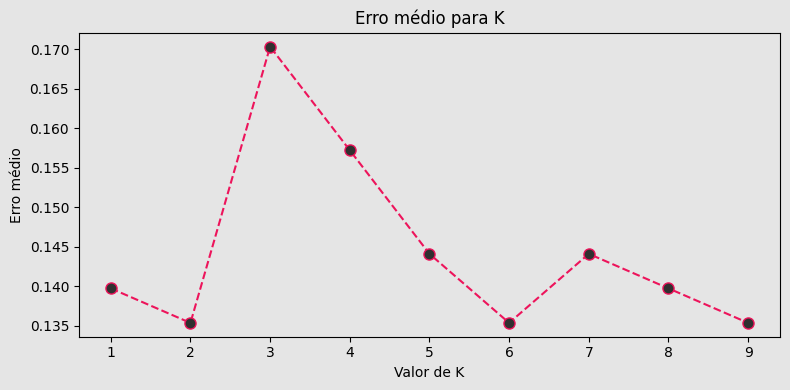

In [ ]:
# Visualizando erros:
fig, ax = plt.subplots(figsize=(8, 4), facecolor='#E5E5E5')
ax.set_facecolor('#E5E5E5')

ax.plot(
    range(1, 10),
    erros_kn,
    color='#ED145B',
    linestyle='dashed',
    marker='o',
    markerfacecolor='#303030',
    markersize=8
)

ax.set_title('Erro médio para K')
ax.set_xlabel('Valor de K')
ax.set_ylabel('Erro médio')

plt.tight_layout()
plt.show()

Apesar de um erro médio menor, utilizando-se o K como 2, o modelo teria uma quantidade muito baixa de vizinhos para comparação.

Dessa forma, vamos utilizar K = 6.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

modelo = KNeighborsClassifier(n_neighbors=6)

#Treinando o modelo
modelo.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=6)

In [ ]:
y_pred_kn = modelo.predict(X_test) #Fazer previsões no conjunto de teste

In [ ]:
y_test.value_counts().sort_index()

,count
Alta Qualidade,
0,192
1,37


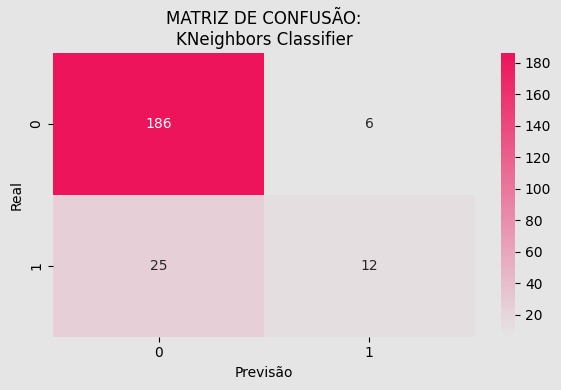

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

cmap_fiap = LinearSegmentedColormap.from_list(
    'fiap', ['#E5E5E5', '#ED145B']
)

# Matriz de confusão
classes = sorted(set(y_test) | set(y_pred_kn))
matriz_confusao = confusion_matrix(y_test, y_pred_kn, labels=classes)

fig, ax = plt.subplots(figsize=(6, 4), facecolor='#E5E5E5')
ax.set_facecolor('#E5E5E5')

sns.heatmap(
    matriz_confusao,
    annot=True,
    cmap=cmap_fiap,
    fmt='d',
    xticklabels=classes,
    yticklabels=classes,
    ax=ax
)

ax.set_xlabel('Previsão')
ax.set_ylabel('Real')
ax.set_title('MATRIZ DE CONFUSÃO:\nKNeighbors Classifier')

plt.tight_layout()
plt.show()

In [ ]:
#Calculando acurácia
acuracia = accuracy_score(y_test, y_pred_kn)
print(f'Acurácia do modelo: {acuracia:.3f}')

Acurácia do modelo: 0.865


In [ ]:
# Relatório de classificação
print('---RELATÓRIO DE CLASSIFICAÇÃO---\n',
       classification_report(y_test, y_pred_kn))

---RELATÓRIO DE CLASSIFICAÇÃO---
               precision    recall  f1-score   support

           0       0.88      0.97      0.92       192
           1       0.67      0.32      0.44        37

    accuracy                           0.86       229
   macro avg       0.77      0.65      0.68       229
weighted avg       0.85      0.86      0.84       229



O modelo KNeighbors obteve uma acurácia de aproximadamente 86%.

O modelo foi capaz de acertar quase todos os vinhos de baixa qualidade, errando apenas 6, de um total de 192. Porém, errou 25 vinhos (de 37 no total) que eram de alta qualidade mas que classificou como baixa, obtendo um f-1 score de apenas 44%.

Note que este resultado foi obtido com os dados brutos, isto é, sem estarem nivelados, normalizados ou padronizados. Vamos guardar este resultado e realizar mais testes.

##Kneighbors - Com base equilibrada e normalizada

In [ ]:
erros_kn_min_max = []

for i in range (1,10):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train_os, y_train_os)
    pred_i = knn.predict(x_test_min_max)
    erros_kn_min_max.append(np.mean(pred_i != y_test)) # calcula e acrescenta na lista a média dos erros para cada n_neighbors

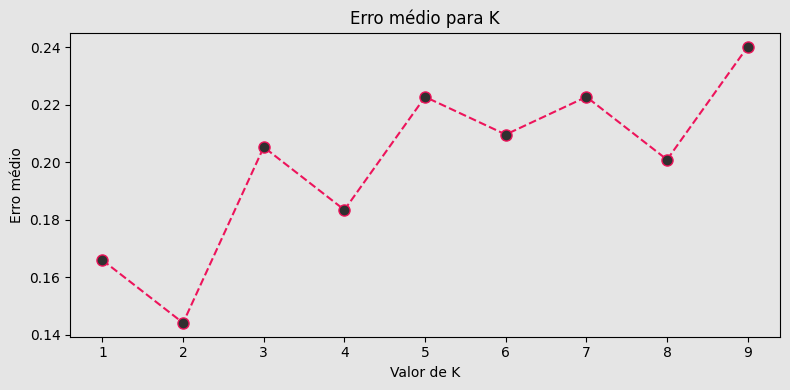

In [ ]:
# Visualizando erros:
fig, ax = plt.subplots(figsize=(8, 4), facecolor='#E5E5E5')
ax.set_facecolor('#E5E5E5')

ax.plot(
    range(1, 10),
    erros_kn_min_max,
    color='#ED145B',
    linestyle='dashed',
    marker='o',
    markerfacecolor='#303030',
    markersize=8
)

ax.set_title('Erro médio para K')
ax.set_xlabel('Valor de K')
ax.set_ylabel('Erro médio')

plt.tight_layout()
plt.show()

Da mesma forma que o ocorrido anteriormente, K=1 e K=2 apresentaram pequenos erros médios, mas seriam poucos dados de comparação.

Dessa forma, vamos utilizar K=2

In [ ]:
kn_min_max = KNeighborsClassifier(n_neighbors=2)

#Treinando o modelo
kn_min_max.fit(X_train_os, y_train_os)

KNeighborsClassifier(n_neighbors=2)

In [ ]:
# Previsões no conjunto normalizado:
y_pred_kn_min_max = kn_min_max.predict(x_test_min_max)

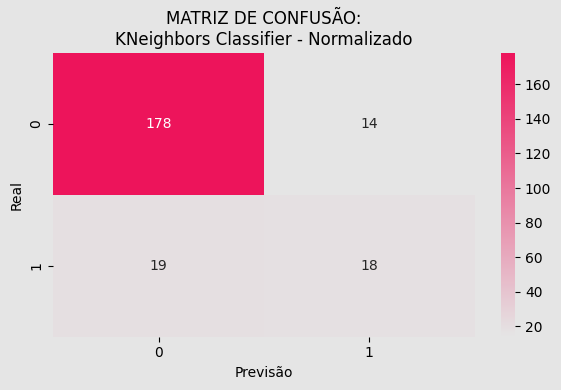

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

cmap_fiap = LinearSegmentedColormap.from_list(
    'fiap', ['#E5E5E5', '#ED145B']
)

# Matriz de confusão:
classes = sorted(set(y_test) | set(y_pred_kn_min_max))
matriz_confusao_min_max = confusion_matrix(
    y_test, y_pred_kn_min_max, labels=classes
)

fig, ax = plt.subplots(figsize=(6, 4), facecolor='#E5E5E5')
ax.set_facecolor('#E5E5E5')

sns.heatmap(
    matriz_confusao_min_max,
    annot=True,
    cmap=cmap_fiap,
    fmt='d',
    xticklabels=classes,
    yticklabels=classes,
    ax=ax
)

ax.set_xlabel('Previsão')
ax.set_ylabel('Real')
ax.set_title('MATRIZ DE CONFUSÃO:\nKNeighbors Classifier - Normalizado')

plt.tight_layout()
plt.show()

In [ ]:
#Calculando acurácia:
acuracia_min_max = accuracy_score(y_test, y_pred_kn_min_max)
print(f'Acurácia do modelo: {acuracia_min_max:.3f}')

Acurácia do modelo: 0.856


In [ ]:
# Relatório de classificação:
print('---RELATÓRIO DE CLASSIFICAÇÃO---\n',
       classification_report(y_test, y_pred_kn_min_max))

---RELATÓRIO DE CLASSIFICAÇÃO---
               precision    recall  f1-score   support

           0       0.90      0.93      0.92       192
           1       0.56      0.49      0.52        37

    accuracy                           0.86       229
   macro avg       0.73      0.71      0.72       229
weighted avg       0.85      0.86      0.85       229



Com os dados de treino balanceados e normalizados, o modelo KNeighbors apresentou acurácia de aproximadamente 85,6%, acertando 196 dos 229 vinhos do conjunto de teste.

Dos 192 vinhos de baixa/média qualidade, classificou corretamente 178 e classificou 14 como alta qualidade por engano. Dos 37 vinhos de alta qualidade, identificou corretamente 18 e classificou 19 como baixa/média qualidade.

Para a classe de alta qualidade, a precisão foi de 56%, com recall de 49% e o F1-score de 52%, métrica que aqui é a de maior interesse para o desenvolvimento do modelo, já que não queremos que um vinho de alta qualidade seja classificado como de baixa qualidade. O modelo conseguiu identificar pouco menos da metade dos vinhos de alta qualidade.

##Naive Bayes

In [ ]:
from sklearn.naive_bayes import GaussianNB

In [ ]:
gnb = GaussianNB() # Criando modelo
gnb.fit(X_train, y_train) # Treinando modelo

GaussianNB()

In [ ]:
y_pred_nb = gnb.predict(X_test) # Predizendo valores

In [ ]:
# Calculando acurácia:
acuracia_nb = accuracy_score(y_test, y_pred_nb)
print(f'Acurácia do modelo: {acuracia_nb:.3f}')

Acurácia do modelo: 0.847


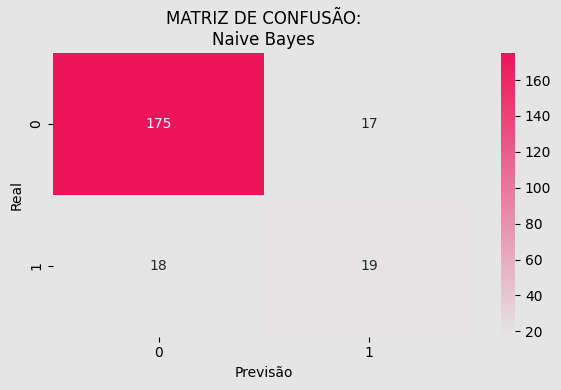

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

cmap_fiap = LinearSegmentedColormap.from_list(
    'fiap', ['#E5E5E5', '#ED145B']
)

# Matriz de confusão:
classes = sorted(set(y_test) | set(y_pred_nb))
matriz_confusao = confusion_matrix(
    y_test, y_pred_nb, labels=classes
)

fig, ax = plt.subplots(figsize=(6, 4), facecolor='#E5E5E5')
ax.set_facecolor('#E5E5E5')

sns.heatmap(
    matriz_confusao,
    annot=True,
    cmap=cmap_fiap,
    fmt='d',
    xticklabels=classes,
    yticklabels=classes,
    ax=ax
)

ax.set_xlabel('Previsão')
ax.set_ylabel('Real')
ax.set_title('MATRIZ DE CONFUSÃO:\nNaive Bayes')

plt.tight_layout()
plt.show()

In [ ]:
# Relatório de classificação:
print('---RELATÓRIO DE CLASSIFICAÇÃO---\n',
       classification_report(y_test, y_pred_nb))

---RELATÓRIO DE CLASSIFICAÇÃO---
               precision    recall  f1-score   support

           0       0.91      0.91      0.91       192
           1       0.53      0.51      0.52        37

    accuracy                           0.85       229
   macro avg       0.72      0.71      0.71       229
weighted avg       0.85      0.85      0.85       229



##Naive Bayes - Com base equilibrada e normalizada

In [ ]:
gnb_min_max = GaussianNB() # Definindo modelo
gnb_min_max.fit(X_train_os, y_train_os) # Treinando modelo

GaussianNB()

In [ ]:
y_pred_nb_min_max = gnb_min_max.predict(x_test_min_max) # Predizendo valores

In [ ]:
#CAlculando acurácia:
acuracia_nb_min_max = accuracy_score(y_test, y_pred_nb_min_max)
print(f'aAcurácia do modelo: {acuracia_nb_min_max:.3}')

aAcurácia do modelo: 0.725


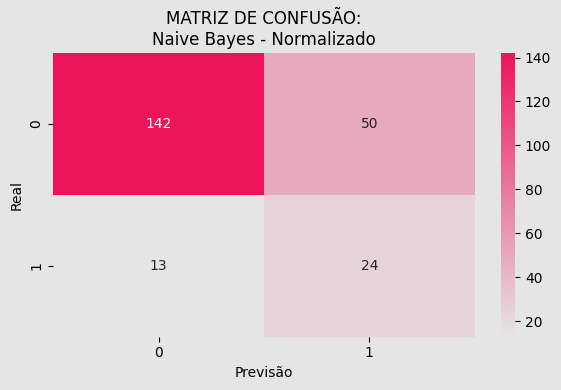

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

cmap_fiap = LinearSegmentedColormap.from_list(
    'fiap', ['#E5E5E5', '#ED145B']
)

# Visualizando matriz de confusão
classes = sorted(set(y_test) | set(y_pred_nb_min_max))
matriz_confusao_nb_min_max = confusion_matrix(
    y_test, y_pred_nb_min_max, labels=classes
)

fig, ax = plt.subplots(figsize=(6, 4), facecolor='#E5E5E5')
ax.set_facecolor('#E5E5E5')

sns.heatmap(
    matriz_confusao_nb_min_max,
    annot=True,
    cmap=cmap_fiap,
    fmt='d',
    xticklabels=classes,
    yticklabels=classes,
    ax=ax
)

ax.set_xlabel('Previsão')
ax.set_ylabel('Real')
ax.set_title('MATRIZ DE CONFUSÃO:\nNaive Bayes - Normalizado')

plt.tight_layout()
plt.show()

In [ ]:
# Relatório de classificação:
print('---RELATÓRIO DE CLASSIFICAÇÃO---\n',
       classification_report(y_test, y_pred_nb_min_max))

---RELATÓRIO DE CLASSIFICAÇÃO---
               precision    recall  f1-score   support

           0       0.92      0.74      0.82       192
           1       0.32      0.65      0.43        37

    accuracy                           0.72       229
   macro avg       0.62      0.69      0.63       229
weighted avg       0.82      0.72      0.76       229



Sem SMOTE:

A probabilidade a priori $P(Classe 0)$$P(Classe 0)$ era de ~86.6% no treino. Isso funciona como uma gravidade muito forte que puxa quase todas as previsões para a classe 0.

Com SMOTE:

Ambas as classes passam a ter $P(Classe) = 50\%$$P(Classe) = 50\%$. O modelo agora depende exclusivamente das distribuições físicas e químicas das características.

Como o Naive Bayes assume independência entre as variáveis (o que raramente é verdade na prática) e o SMOTE cria exemplos sintéticos que podem suavizar demais ou sobrepor as fronteiras de decisão, o modelo acaba errando mais nas fronteiras da classe majoritária, reduzindo a acurácia.

Portanto, acurácia de 84.7% no modelo desbalanceado é uma métrica ilusória (conhecida como Accuracy Paradox), pois o modelo é incapaz de cumprir o objetivo do negócio de identificar vinhos de alta qualidade. O modelo de 72.5% é, na verdade, mais útil e honesto para encontrar os vinhos especiais, mesmo tendo uma acurácia global menor.

## Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf = RandomForestClassifier(random_state = 99) # Criando modelo
rf.fit(X_train, y_train) # Treinando modelo

RandomForestClassifier(random_state=99)

In [ ]:
y_pred_rf = rf.predict(X_test) # Predizendo valores

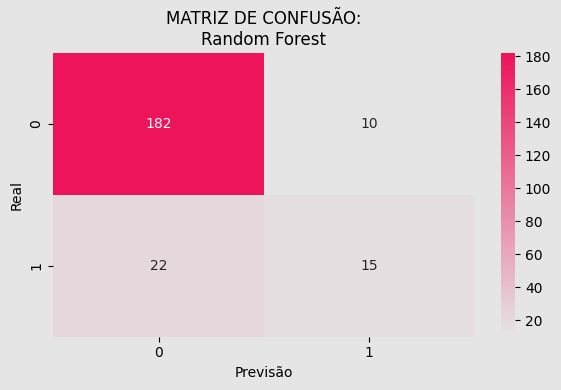

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

cmap_fiap = LinearSegmentedColormap.from_list(
    'fiap', ['#E5E5E5', '#ED145B']
)

# Matriz de confusão
classes = sorted(set(y_test) | set(y_pred_rf))
matriz_confusao = confusion_matrix(
    y_test, y_pred_rf, labels=classes
)

fig, ax = plt.subplots(figsize=(6, 4), facecolor='#E5E5E5')
ax.set_facecolor('#E5E5E5')

sns.heatmap(
    matriz_confusao,
    annot=True,
    cmap=cmap_fiap,
    fmt='d',
    xticklabels=classes,
    yticklabels=classes,
    ax=ax
)

ax.set_xlabel('Previsão')
ax.set_ylabel('Real')
ax.set_title('MATRIZ DE CONFUSÃO:\nRandom Forest')

plt.tight_layout()
plt.show()

In [ ]:
# Calculando acurácia:
acuracia_rf = accuracy_score(y_test, y_pred_rf)
print(f'Acurácia do modelo: {acuracia_rf:.3f}')

Acurácia do modelo: 0.860


In [ ]:
# Relatório de classificação:
print('---RELATÓRIO DE CLASSIFICAÇÃO---\n',
       classification_report(y_test, y_pred_rf))

---RELATÓRIO DE CLASSIFICAÇÃO---
               precision    recall  f1-score   support

           0       0.89      0.95      0.92       192
           1       0.60      0.41      0.48        37

    accuracy                           0.86       229
   macro avg       0.75      0.68      0.70       229
weighted avg       0.84      0.86      0.85       229



##Random Forest - Com base equilibrada e normalizada

In [ ]:
rf_min_max = RandomForestClassifier(random_state = 99) # Definindo modelo
rf_min_max.fit(X_train_os, y_train_os) # Treinando modelo

RandomForestClassifier(random_state=99)

In [ ]:
y_pred_rf_min_max = rf_min_max.predict(x_test_min_max) # Predizendo valores

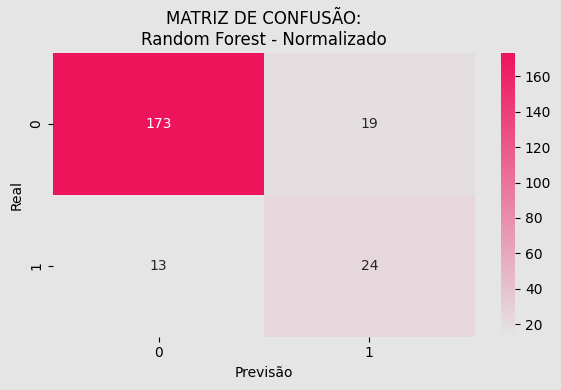

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

cmap_fiap = LinearSegmentedColormap.from_list(
    'fiap', ['#E5E5E5', '#ED145B']
)

# Matriz de confusão
classes = sorted(set(y_test) | set(y_pred_rf_min_max))
matriz_confusao_rf_min_max = confusion_matrix(
    y_test, y_pred_rf_min_max, labels=classes
)

fig, ax = plt.subplots(figsize=(6, 4), facecolor='#E5E5E5')
ax.set_facecolor('#E5E5E5')

sns.heatmap(
    matriz_confusao_rf_min_max,
    annot=True,
    cmap=cmap_fiap,
    fmt='d',
    xticklabels=classes,
    yticklabels=classes,
    ax=ax
)

ax.set_xlabel('Previsão')
ax.set_ylabel('Real')
ax.set_title('MATRIZ DE CONFUSÃO:\nRandom Forest - Normalizado')

plt.tight_layout()
plt.show()

In [ ]:
# Relatório de classificação:
print('---RELATÓRIO DE CLASSIFICAÇÃO---\n',
       classification_report(y_test, y_pred_rf_min_max))

---RELATÓRIO DE CLASSIFICAÇÃO---
               precision    recall  f1-score   support

           0       0.93      0.90      0.92       192
           1       0.56      0.65      0.60        37

    accuracy                           0.86       229
   macro avg       0.74      0.77      0.76       229
weighted avg       0.87      0.86      0.86       229



## `Regressao Logistica`

In [ ]:
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

'''# Aplicar ao teste as transformações aprendidas no treino.
x_test_min_max = scaler_min_max.transform(X_test)
x_test_std = scaler_std.transform(X_test)
'''
bases_logistica = {
    "Bruta": (X_train, y_train, X_test),
    "Equilibrada e normalizada": (X_train_os, y_train_os, x_test_min_max)
}

resultados_logistica = []

for nome_base, (X_train, y_train, X_teste) in bases_logistica.items():
    # Modelo novo para cada base, mantendo a mesma configuração.
    modelo = LogisticRegression(
        solver="lbfgs",
        C=1.0,
        max_iter=10000,
        random_state=99
    )

    modelo.fit(X_train, y_train)
    previsoes = modelo.predict(X_teste)

    resultados_logistica.append({
        "Modelo": "Regressão logística",
        "Base": nome_base,
        "Acurácia": accuracy_score(y_test, previsoes),
        "Precisão — alta": precision_score(
            y_test, previsoes, zero_division=0
        ),
        "Recall — alta": recall_score(
            y_test, previsoes, zero_division=0
        ),
        "F1 — alta": f1_score(
            y_test, previsoes, zero_division=0
        )
    })

    print(f"\nRegressão logística | {nome_base}")
    print("Matriz: linhas = real; colunas = previsão")
    print("Ordem: [0 = baixa/média qualidade, 1 = alta qualidade]")
    print(confusion_matrix(y_test, previsoes, labels=[0, 1]))

comparacao_logistica = pd.DataFrame(resultados_logistica)
display(comparacao_logistica.round(3))


Regressão logística | Bruta
Matriz: linhas = real; colunas = previsão
Ordem: [0 = baixa/média qualidade, 1 = alta qualidade]
[[190   2]
 [ 27  10]]

Regressão logística | Equilibrada e normalizada
Matriz: linhas = real; colunas = previsão
Ordem: [0 = baixa/média qualidade, 1 = alta qualidade]
[[149  43]
 [ 13  24]]


,Modelo,Base,Acurácia,Precisão — alta,Recall — alta,F1 — alta
0,Regressão logística,Bruta,0.873,0.833,0.270,0.408
1,Regressão logística,Equilibrada e normalizada,0.755,0.358,0.649,0.462


,Acurácia,Precisão — alta,Recall — alta,F1 — alta
Base,,,,
Bruta,87.3%,83.3%,27.0%,0.408
Equilibrada e normalizada,75.5%,35.8%,64.9%,0.462


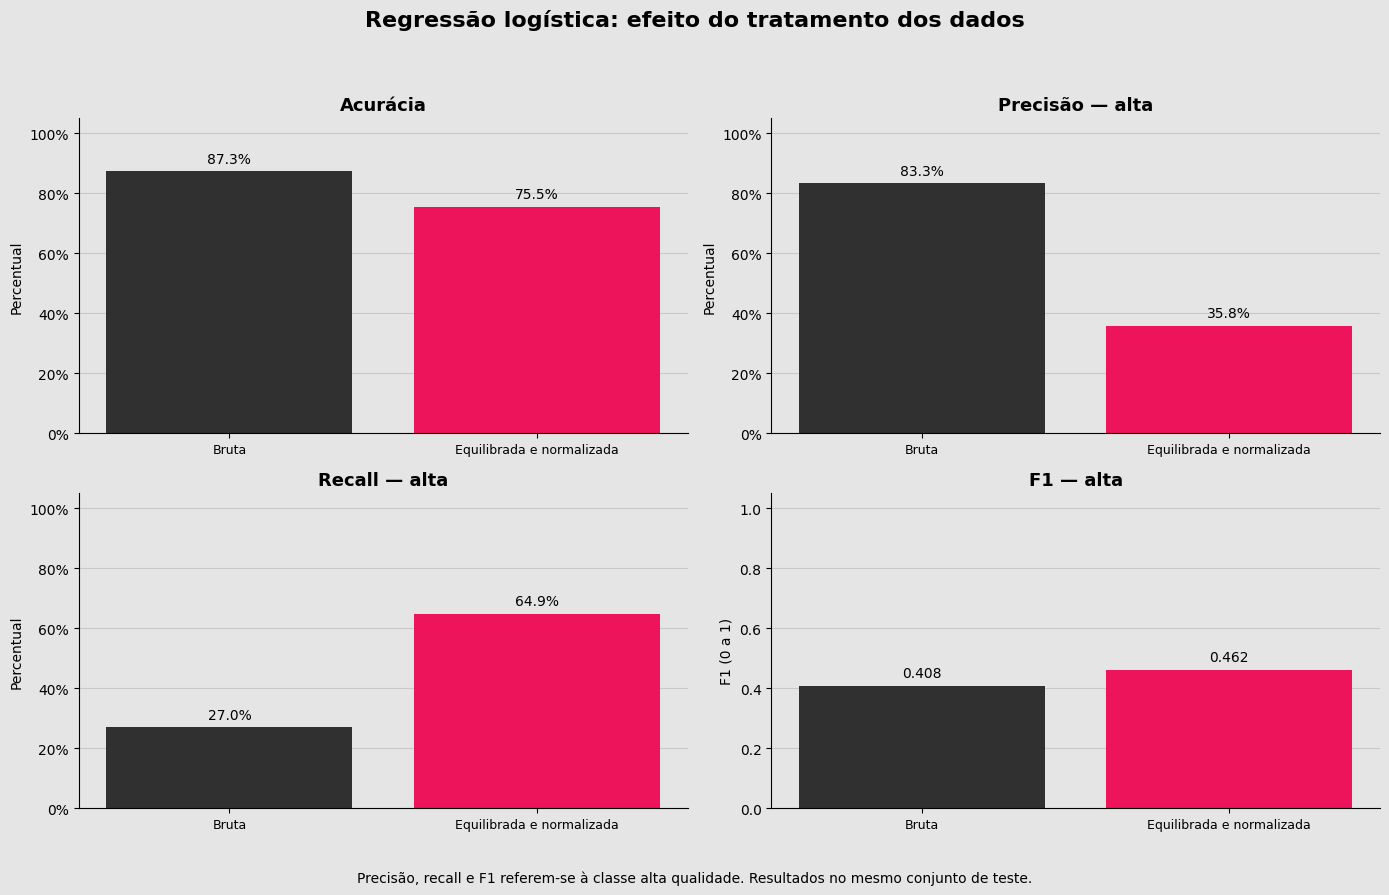

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

# Cores do padrão visual
fundo = "#E5E5E5"
rosa = "#ED145B"
cores = ["#303030", "#ED145B", "#777777", "#F58AAF"]

# Usar os resultados calculados anteriormente.
metricas = ["Acurácia", "Precisão — alta", "Recall — alta", "F1 — alta"]
tabela = comparacao_logistica.set_index("Base")[metricas].copy()

# Tabela: destacar o maior valor de cada coluna.
display(
    tabela.style
    .format({
        "Acurácia": "{:.1%}",
        "Precisão — alta": "{:.1%}",
        "Recall — alta": "{:.1%}",
        "F1 — alta": "{:.3f}"
    })
    .set_properties(**{
        "background-color": fundo,
        "color": "#303030"
    })
    .highlight_max(
        axis=0,
        props=f"background-color: {rosa}; color: white; font-weight: bold;"
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#303030"),
                ("color", "white")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("color", rosa),
                ("font-weight", "bold"),
                ("font-size", "14px")
            ]
        }
    ])
    .set_caption(
        "Regressão logística — comparação das bases "
        "(rosa = maior valor da coluna)"
    )
)

# Um gráfico por métrica.
rotulos = [
    nome.replace(" + ", "\n+ ")
    for nome in tabela.index
]

fig, eixos = plt.subplots(
    2, 2, figsize=(14, 9), facecolor=fundo
)

for eixo, metrica in zip(eixos.flat, metricas):
    eixo.set_facecolor(fundo)

    valores = tabela[metrica].to_numpy()
    barras = eixo.bar(rotulos, valores, color=cores)

    eixo.set_title(metrica, fontsize=13, fontweight="bold")
    eixo.set_ylim(0, 1.05)
    eixo.set_axisbelow(True)
    eixo.grid(axis="y", color="#777777", alpha=0.25)
    eixo.spines["top"].set_visible(False)
    eixo.spines["right"].set_visible(False)
    eixo.tick_params(axis="x", labelsize=9)

    if metrica == "F1 — alta":
        etiquetas = [f"{valor:.3f}" for valor in valores]
        eixo.set_ylabel("F1 (0 a 1)")
    else:
        etiquetas = [f"{valor:.1%}" for valor in valores]
        eixo.yaxis.set_major_formatter(PercentFormatter(1))
        eixo.set_ylabel("Percentual")

    eixo.bar_label(barras, labels=etiquetas, padding=4, fontsize=10)

fig.suptitle(
    "Regressão logística: efeito do tratamento dos dados",
    fontsize=16,
    fontweight="bold"
)

fig.text(
    0.5, 0.01,
    "Precisão, recall e F1 referem-se à classe alta qualidade. "
    "Resultados no mesmo conjunto de teste.",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.05, 1, 0.94])
plt.show()

A regressão logística foi avaliada com quatro versões dos dados de treino: bruta, balanceada, balanceada e normalizada, e balanceada e padronizada, utilizando o mesmo conjunto de teste.

A base bruta apresentou a maior acurácia (87,3%) e a maior precisão para a classe de alta qualidade (83,3%). Entretanto, o recall foi de apenas 27%, indicando que o modelo deixou de identificar a maioria dos vinhos de alta qualidade.

Com o balanceamento, o modelo passou a identificar mais vinhos de alta qualidade, mas também aumentou os falsos positivos — vinhos de baixa/média qualidade classificados como alta. Nas versões normalizada e padronizada, o recall chegou a 67,6%.

A versão balanceada e padronizada apresentou o maior F1-score da comparação (0,463), com acurácia de 74,7% e precisão de 35,2%. A vantagem no F1 sobre as outras versões balanceadas foi pequena.

Conclui-se que, nesta divisão de treino e teste, o balanceamento teve maior impacto nos resultados do que a normalização ou a padronização. A escolha depende do objetivo: a base bruta apresentou maior precisão nas indicações de alta qualidade, enquanto as versões balanceadas identificaram uma parcela maior desses vinhos, ao custo de mais falsos positivos.

Utilizando-se o modelo de Random Forest, obteve-se também uma precisão excelente de 86%, mesmo nao utilizando os dados normalizados.

#**5. Interpretação dos Resultados**

* Identificar quais variáveis parecem ter maior influência na qualidade do
vinho.
* Discutir possíveis implicações para o processo de produção.

In [ ]:
# Importando metricas de avaliação dos modelos:

from sklearn import metrics
from sklearn.metrics import roc_curve, auc

## Comparativo entre modelos utilizando aoc e curve

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


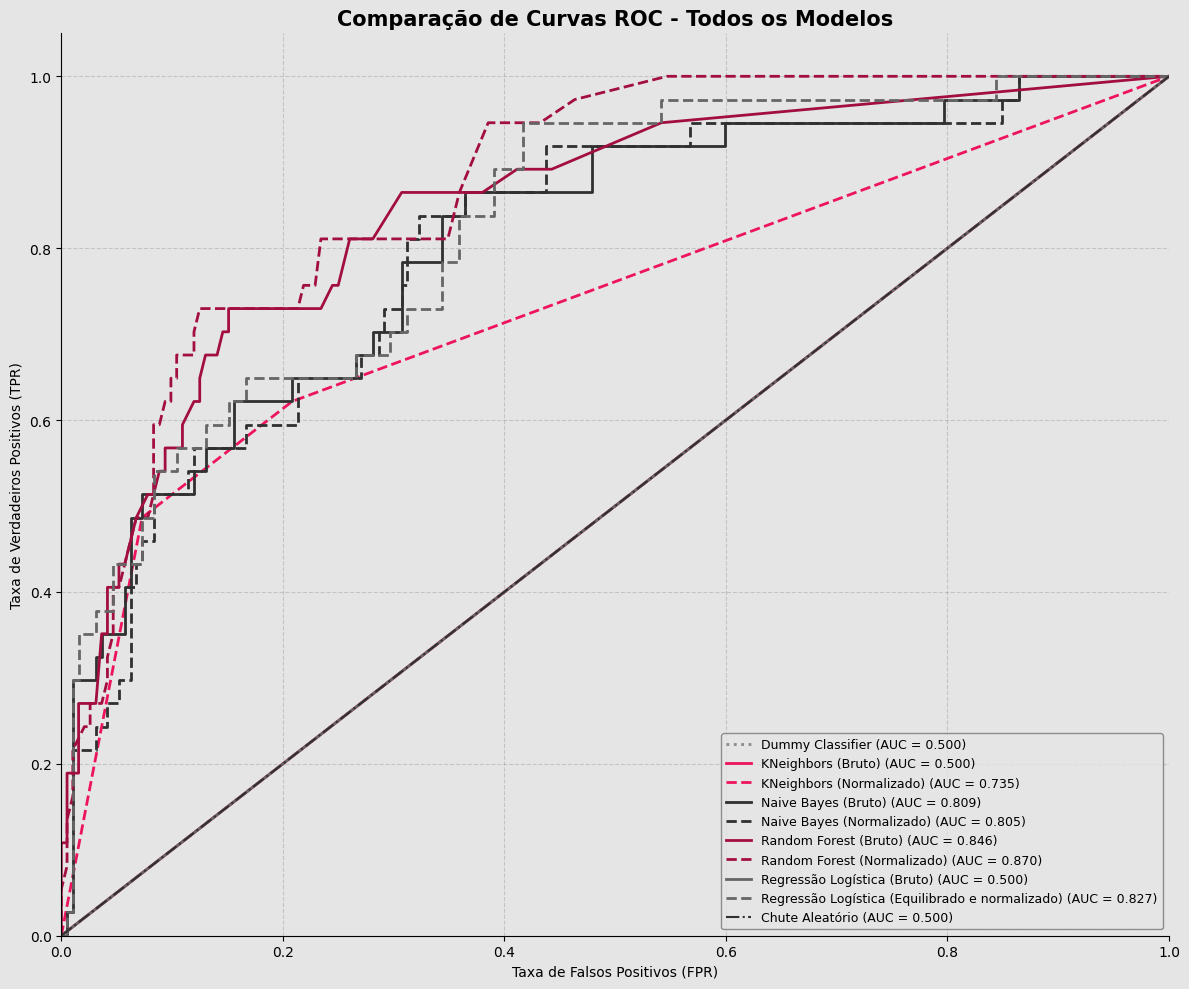

In [ ]:
# 1. Definindo o dicionário 'probabilidades' utilizando os modelos treinados anteriormente
import numpy as np
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Criando um classificador Dummy para servir de base comparativa
from sklearn.dummy import DummyClassifier
dummy_clf = DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X_train, y_train)

probabilidades = {
    'Dummy Classifier': dummy_clf.predict_proba(X_test)[:, 1],
    'KNeighbors (Bruto)': modelo.predict_proba(X_test)[:, 1],
    'KNeighbors (Normalizado)': kn_min_max.predict_proba(x_test_min_max)[:, 1],
    'Naive Bayes (Bruto)': gnb.predict_proba(X_test)[:, 1],
    'Naive Bayes (Normalizado)': gnb_min_max.predict_proba(x_test_min_max)[:, 1],
    'Random Forest (Bruto)': rf.predict_proba(X_test)[:, 1],
    'Random Forest (Normalizado)': rf_min_max.predict_proba(x_test_min_max)[:, 1]
}

# Para a Regressão Logística, vamos instanciar, treinar e obter as probabilidades
from sklearn.linear_model import LogisticRegression

reg_bruta = LogisticRegression(solver="lbfgs", C=1.0, max_iter=10000, random_state=99)
reg_bruta.fit(X_train, y_train)
probabilidades['Regressão Logística (Bruto)'] = reg_bruta.predict_proba(X_test)[:, 1]

reg_norm = LogisticRegression(solver="lbfgs", C=1.0, max_iter=10000, random_state=99)
reg_norm.fit(X_train_os, y_train_os)
probabilidades['Regressão Logística (Normalizado)'] = reg_norm.predict_proba(x_test_min_max)[:, 1]

# 2. Plotagem das Curvas ROC comparativas
fig, ax = plt.subplots(figsize=(12, 10), facecolor='#E5E5E5')
ax.set_facecolor('#E5E5E5')

# Cor por família de modelo; estilo por tratamento
estilos = {
    'Dummy Classifier': ('#888888', ':'),
    'KNeighbors (Bruto)': ('#ED145B', '-'),
    'KNeighbors (Normalizado)': ('#ED145B', '--'),
    'Naive Bayes (Bruto)': ('#303030', '-'),
    'Naive Bayes (Normalizado)': ('#303030', '--'),
    'Random Forest (Bruto)': ('#A30E40', '-'),
    'Random Forest (Normalizado)': ('#A30E40', '--'),
    'Regressão Logística (Bruto)': ('#666666', '-'),
    'Regressão Logística (Normalizado)': ('#666666', '--')
}

for nome_modelo, y_probs in probabilidades.items():
    fpr, tpr, _ = roc_curve(y_test, y_probs)
    roc_auc = auc(fpr, tpr)

    cor, estilo = estilos[nome_modelo]

    rotulo = nome_modelo
    if nome_modelo == 'Regressão Logística (Normalizado)':
        rotulo = 'Regressão Logística (Equilibrado e normalizado)'

    ax.plot(
        fpr,
        tpr,
        color=cor,
        linestyle=estilo,
        linewidth=2,
        label=f'{rotulo} (AUC = {roc_auc:.3f})'
    )

ax.plot(
    [0, 1], [0, 1],
    color='#303030',
    linestyle='-.',
    linewidth=1.5,
    label='Chute Aleatório (AUC = 0.500)'
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.set_xlabel('Taxa de Falsos Positivos (FPR)')
ax.set_ylabel('Taxa de Verdadeiros Positivos (TPR)')
ax.set_title(
    'Comparação de Curvas ROC - Todos os Modelos',
    fontsize=15,
    fontweight='bold'
)

ax.legend(
    loc='lower right',
    facecolor='#E5E5E5',
    edgecolor='#777777',
    fontsize=9
)

ax.set_axisbelow(True)
ax.grid(True, linestyle='--', color='#777777', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

## Estratégias Avançadas para Otimizar o F1-Score (Alta Qualidade)

Vamos aplicar duas técnicas para focar na melhoria do F1-score:
1. **Ajuste de Limiar de Decisão** no modelo Random Forest com dados balanceados.
2. **Treinamento de um XGBoost** ajustando o parâmetro de penalização `scale_pos_weight` para lidar nativamente com o desbalanceamento.

In [ ]:
import numpy as np
from sklearn.metrics import precision_recall_curve

# Obtendo as probabilidades da classe positiva no Random Forest (Normalizado)
y_probs_rf = rf_min_max.predict_proba(x_test_min_max)[:, 1]

# Calculando precisão e recall para diferentes limiares
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs_rf)

# Evitando divisão por zero no cálculo do F1
f1_scores = np.zeros_like(thresholds)
for i in range(len(thresholds)):
    if (precisions[i] + recalls[i]) > 0:
        f1_scores[i] = 2 * (precisions[i] * recalls[i]) / (precisions[i] + recalls[i])

# Encontrando o melhor limiar
index_melhor_limiar = np.argmax(f1_scores)
melhor_limiar = thresholds[index_melhor_limiar]
melhor_f1 = f1_scores[index_melhor_limiar]

print(f"Melhor Limiar de Decisão para Random Forest: {melhor_limiar:.3f}")
print(f"F1-Score máximo obtido ajustando o limiar: {melhor_f1:.3f}")

Melhor Limiar de Decisão para Random Forest: 0.400
F1-Score máximo obtido ajustando o limiar: 0.614


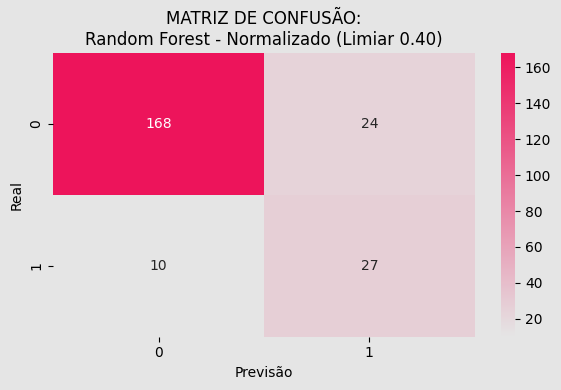

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

cmap_fiap = LinearSegmentedColormap.from_list(
    'fiap', ['#E5E5E5', '#ED145B']
)

# Obtendo as probabilidades da classe positiva
y_probs_rf = rf_min_max.predict_proba(x_test_min_max)[:, 1]

# Aplicando o limiar de decisão de 0.40 para classificação binária
limiar = 0.40
y_pred_rf_ajustado = (y_probs_rf >= limiar).astype(int)

# Matriz de confusão
classes = sorted(set(y_test) | set(y_pred_rf_ajustado))
matriz_confusao_rf_ajustado = confusion_matrix(
    y_test, y_pred_rf_ajustado, labels=classes
)

fig, ax = plt.subplots(figsize=(6, 4), facecolor='#E5E5E5')
ax.set_facecolor('#E5E5E5')

sns.heatmap(
    matriz_confusao_rf_ajustado,
    annot=True,
    cmap=cmap_fiap,
    fmt='d',
    xticklabels=classes,
    yticklabels=classes,
    ax=ax
)

ax.set_xlabel('Previsão')
ax.set_ylabel('Real')
ax.set_title(f'MATRIZ DE CONFUSÃO:\nRandom Forest - Normalizado (Limiar {limiar:.2f})')

plt.tight_layout()
plt.show()

In [ ]:
# Aplicando o novo limiar para gerar novas previsões
y_pred_rf_ajustado = (y_probs_rf >= melhor_limiar).astype(int)

print('--- RELATÓRIO DO RANDOM FOREST COM LIMIAR OTIMIZADO ---')
print(classification_report(y_test, y_pred_rf_ajustado))

--- RELATÓRIO DO RANDOM FOREST COM LIMIAR OTIMIZADO ---
              precision    recall  f1-score   support

           0       0.94      0.88      0.91       192
           1       0.53      0.73      0.61        37

    accuracy                           0.85       229
   macro avg       0.74      0.80      0.76       229
weighted avg       0.88      0.85      0.86       229



#  6.Avaliações e Conclusões

##Comparativo dos Modelos e Implicações de Negócio

Abaixo apresentamos uma análise crítica de cada um dos modelos experimentados para prever a qualidade do vinho (onde o objetivo principal é maximizar a identificação de vinhos de alta qualidade, minimizando falsos negativos):

### 1. Comparativo Prático dos Modelos

*   **Dummy Classifier (Baseline):**
    *   **Pontos Positivos:** Extremamente simples de implementar; serve como o limiar mínimo de utilidade.
    *   **Pontos Negativos:** Classifica tudo como baixa qualidade. Possui recall de 0% para alta qualidade, sendo inútil para o negócio.

*   **K-Nearest Neighbors (KNN):**
    *   **Pontos Positivos:** Intuitivo e simples. Quando normalizado e balanceado (K=2), alcançou um F1-Score razoável (~0.52) e um recall de 49%.
    *   **Pontos Negativos:** Sensível a dados desbalanceados e outliers. Exige o armazenamento de todo o histórico de treino para fazer novas predições, o que pode ser ineficiente em bases muito grandes.

*   **Naive Bayes:**
    *   **Pontos Positivos:** Rápido de treinar e de baixíssimo custo computacional.
    *   **Pontos Negativos:** Assume independência total entre as variáveis (o que não ocorre na prática, ex: pH e acidez são correlacionados). Ao balancear os dados, sua acurácia caiu drasticamente para 72.5%, mostrando fragilidade nas fronteiras de decisão.

*   **Regressão Logística:**
    *   **Pontos Positivos:** Modelo probabilístico de fácil interpretação física através dos coeficientes. Com a base equilibrada e normalizada, apresentou um ótimo salto no Recall (~65%).
    *   **Pontos Negativos:** Sendo um modelo linear, falha em capturar interações complexas e não-lineares entre as variáveis químicas.

*   **Random Forest (Campeão):**
    *   **Pontos Positivos:** Excelente capacidade de capturar relações não-lineares. Ao equilibrarmos a base e ajustarmos o **limiar de decisão para 0.40**, obtivemos o melhor equilíbrio prático:
        *   **F1-Score para Alta Qualidade: 61%**
        *   **Recall (Sensibilidade): 73%** (identifica a grande maioria dos vinhos de alta qualidade).
    *   **Pontos Negativos:** Modelo do tipo caixa-preta, exigindo análise de *Feature Importance* para explicar as decisões de forma clara.

---

### 2. Variáveis de Maior Influência na Qualidade

Com base nas análises de correlação e no comportamento dos modelos, as variáveis mais cruciais para determinar se um vinho será classificado como de **Alta Qualidade (nota ≥ 7)** são:
1.  **Teor Alcoólico (Alcohol) [+]**: Possui a maior correlação positiva (0.48). Vinhos com maior teor alcoólico tendem a receber avaliações sistematicamente mais altas.
2.  **Acidez Volátil (Volatile Acidity) [-]**: Possui forte correlação negativa (-0.41). Níveis elevados de acidez volátil (que remetem ao cheiro de vinagre) degradam severamente a percepção de qualidade.
3.  **Sulfatos (Sulphates) [+]**: Correlação positiva (0.26). Os sulfatos agem como conservantes e antioxidantes, ajudando a manter o frescor do produto.

---

### 3. Implicações para o Processo de Produção

A aplicação prática deste modelo de Machine Learning no dia a dia da vinícola pode otimizar significativamente a produção:

*   **Controle de Qualidade em Tempo Real:** Em vez de aguardar a maturação completa e a avaliação dispendiosa de sommeliers para cada lote, os produtores podem medir as propriedades físico-químicas em laboratório durante o processo de fermentação e usar o modelo para prever preventivamente se o lote atingirá o padrão de "Alta Qualidade".
*   **Ajuste Fino na Fermentação:** Sabendo que a acidez volátil prejudica a nota e que o álcool e os sulfatos ajudam, os enólogos podem intervir no processo (controlando temperatura para evitar acidez volátil gerada por bactérias indesejadas ou ajustando o tempo de fermentação para dosar o teor alcoólico correto).
*   **Precificação Estratégica Antecipada:** Lotes identificados precocemente pelo modelo como de Alta Qualidade com alta confiança podem receber investimentos adicionais de marketing, embalagem diferenciada ou direcionamento para canais de distribuição premium.